## Reproducibility Note

The outputs shown in this notebook were generated during the completed Google Colab experimental runtime and have been saved for assessment.

During the development of this project, a downloaded version of the CIFAR-10 files were uploaded and kept in the active Colab runtime to avoid repeatedly downloading and preparing the dataset between experimental runs. This was due to the very slow downloading time for the CIFAR-10 dataset.

As required for this project, the data-loading code has been edited so that it is self-contained and so that the notebook can be executed from a fresh Colab runtime without requiring files from the original session.




## CIFAR-10 Data Loading and Exploration ##

The CIFAR-10 dataset is used for this project. It contains 60,000 RGB images of size 32×32 pixels, divided into 50,000 training images and 10,000 testing images across 10 classes.  


This first cell imports the required libraries, sets a random seed for reproducibility, and defines the batch size and local data directory. A batch size of 128 is used as an initial value to provide a reasonable balance between memory usage and training efficiency for a dataset of 50,000 images.

Two DataLoaders are then created. The training DataLoader uses shuffling so that the order of training examples changes between epochs, while the test DataLoader keeps a fixed order because shuffling is not required for evaluation.

Finally,a few checks are carried out to ensure the data has loaded correctly and that all the the datset sizes, image sizes and classes are as expected.


In [1]:
from pathlib import Path
from collections import Counter
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torchvision
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid


SEED = 42
BATCH_SIZE = 128
DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

train_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=test_transform
)


class_names = train_dataset.classes
class_to_index = train_dataset.class_to_idx
number_of_classes = len(class_names)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)


print("Training examples:", len(train_dataset))
print("Testing examples:", len(test_dataset))
print("Classes:", train_dataset.classes)


sample_image, sample_label = train_dataset[0]

print("\nSingle image shape:", sample_image.shape)
print("Single image label:", sample_label, "=", train_dataset.classes[sample_label])


batch_images, batch_labels = next(iter(train_loader))
print("\nBatch image shape:", batch_images.shape)
print("Batch label shape:", batch_labels.shape)

assert len(train_dataset) == 50000
assert len(test_dataset) == 10000
assert sample_image.shape == (3, 32, 32)
assert batch_images.shape[1:] == (3, 32, 32)

print("\nData loading checks passed.")


Training examples: 50000
Testing examples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Single image shape: torch.Size([3, 32, 32])
Single image label: 6 = frog

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])

Data loading checks passed.


## Training Preprocessing ##

Before training, the CIFAR-10 images were preprocessed using simple data augmentation and normalization.

Random cropping with padding and horizontal flipping were applied only to the training set to increase variation and reduce dependence on exact object position. A padding of 4 pixels was chosen to introduce small random translations while keeping the final image size at 32×32. This can be tuned later if required.

Both the training and test images were normalized using the calculated CIFAR-10 training-set channel means and standard deviations to place the inputs on a consistent scale and support more stable optimisation.

The datasets were then reloaded with these transformations and new DataLoaders were created to provide the final training and evaluation batches.

In [2]:
calculate_mean_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

temp_loader = DataLoader(
    calculate_mean_dataset,
    batch_size=128,
    shuffle=False
)

channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
num_pixels = 0

for images, _ in temp_loader:

    channel_sum += images.sum(dim=[0, 2, 3])
    channel_squared_sum += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += images.size(0) * images.size(2) * images.size(3)

mean = channel_sum / num_pixels
std = (channel_squared_sum / num_pixels - mean ** 2).sqrt()

print("Mean:", mean)
print("Std:", std)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=False,
    transform=test_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


Mean: tensor([0.4914, 0.4822, 0.4465])
Std: tensor([0.2470, 0.2435, 0.2616])


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


Using device: cuda


## SIMPLE PIPELINE CHECK ##

Before implementing the required custom architecture, a small conventional CNN was trained for two epochs to verify that the preprocessing, DataLoader, forward pass, cross-entropy loss, backpropagation and optimizer were functioning correctly.

The training accuracy increased from 39.48% to 50.55% between epoch 1 and 2. This confirmed that the training pipeline was working correctly, so the custom architecture could then be implemented.


In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 10)
        )

    def forward(self, x):
        return self.net(x)

model = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


for epoch in range(2):

    model.train()

    correct = 0
    total = 0
    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = 100 * correct / total
    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}, "
        f"Training Accuracy = {train_accuracy:.2f}%"
    )


Epoch 1: Loss = 1.6776, Training Accuracy = 39.48%
Epoch 2: Loss = 1.3852, Training Accuracy = 50.55%


## Basic Intermediate Block Architecture ##


The required model is built from a sequence of intermediate blocks followed by an output block.

The following image is a diagram I made using powerpoint representing the architecture of each intermediate block.


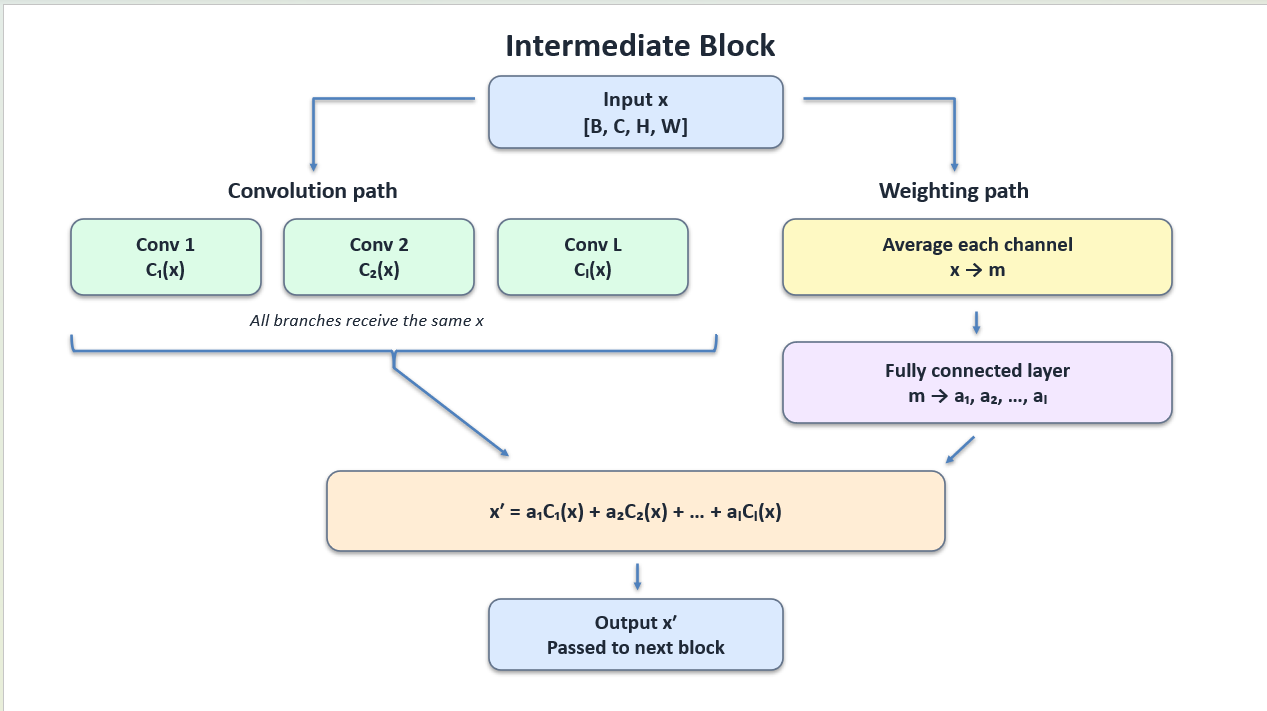

As we can see, within each intermediate block, several independent convolutional layers receive the same input `x`. Because one convolutional branch does not depend on the output of another branch, the branches form a parallel structure rather than a conventional sequential CNN. Each branch can therefore learn a different transformation of the same input feature representation.

A separate weighting path also receives the same input `x`. The spatial values in each channel are averaged to produce a compact vector `m`. This vector is passed through a fully connected layer to produce one coefficient for each convolutional branch. These coefficients determine how strongly each branch contributes to the output of the block.

Importantly, the weighting path does not examine the convolution outputs before producing the coefficients. The coefficients are predicted directly from a summary of the current block input. The block output is then calculated as a weighted sum of the convolutional outputs:


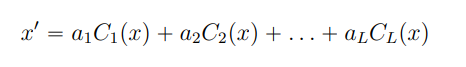


The number of convolutional branches, their kernel sizes, and the number of output channels are hyperparameters and are not fixed by the project specification. For the initial baseline, three branches with kernel sizes 1×1, 3×3 and 5×5 are used so that the same input can be processed at different spatial scales.

All convolutional branches within a block must produce tensors with the same shape so that their outputs can be combined. Padding is therefore used to preserve the spatial dimensions.

As the network becomes deeper, the input to later blocks is no longer the original RGB image but the feature maps produced by previous blocks. Therefore, the channel averages used by later weighting paths summarise learned features rather than simply the average red, green and blue values.

In [5]:
import torch
import torch.nn as nn


class IntermediateBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_sizes):
        super().__init__()

        self.num_branches = len(kernel_sizes)
        self.convs = nn.ModuleList([
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=k,
                padding=k // 2
            )
            for k in kernel_sizes
        ])

        # Produces one weight for each convolution branch
        self.gate = nn.Linear(
            in_channels,
            self.num_branches
        )

    def forward(self, x):


        channel_means = x.mean(dim=(2, 3))
        weights = self.gate(channel_means)

        branch_outputs = [
            conv(x) for conv in self.convs
        ]
        branch_outputs = torch.stack(
            branch_outputs,
            dim=1
        )


        weights = weights[:, :, None, None, None]
        output = (
            weights * branch_outputs
        ).sum(dim=1)

        return output


## Combining Intermediate Blocks ##

In [6]:
class BasicCustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.blocks = nn.ModuleList([
            IntermediateBlock(3, 32, [1, 3, 5]),
            IntermediateBlock(32, 64, [1, 3, 5])
        ])

        self.output_layer = nn.Linear(64, 10)

    def forward(self, x):

        for block in self.blocks:
            x = block(x)

        m = x.mean(dim=(2, 3))
        logits = self.output_layer(m)

        return logits


Running the model and observing results

In [7]:
criterion = nn.CrossEntropyLoss()
model = BasicCustomCNN().to(device)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

NUM_EPOCHS = 10

batch_losses = []
train_accuracies = []
test_accuracies = []

#Training

for epoch in range(NUM_EPOCHS):

    model.train()

    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        batch_losses.append(loss.item())

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = 100 * correct / total
    train_accuracies.append(train_accuracy)


    # Testing
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    test_accuracy = 100 * correct / total
    test_accuracies.append(test_accuracy)


    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )


Epoch 1/10 | Train Accuracy: 21.47% | Test Accuracy: 23.80%
Epoch 2/10 | Train Accuracy: 23.88% | Test Accuracy: 24.76%
Epoch 3/10 | Train Accuracy: 23.95% | Test Accuracy: 23.79%
Epoch 4/10 | Train Accuracy: 24.32% | Test Accuracy: 23.96%
Epoch 5/10 | Train Accuracy: 24.35% | Test Accuracy: 26.68%
Epoch 6/10 | Train Accuracy: 24.75% | Test Accuracy: 24.77%
Epoch 7/10 | Train Accuracy: 24.99% | Test Accuracy: 25.31%
Epoch 8/10 | Train Accuracy: 25.47% | Test Accuracy: 26.67%
Epoch 9/10 | Train Accuracy: 25.63% | Test Accuracy: 26.63%
Epoch 10/10 | Train Accuracy: 26.04% | Test Accuracy: 26.72%



## Potential Directions for Improvement

Training and testing accuracy remained close throughout the run, suggesting that the baseline model was not overfitting and instead had limited representational capacity.

The baseline model achieved a best test accuracy of 26.72% after 10 epochs, with a final training accuracy of 26.04%.

The highest accuracy is still relatively low however understandable since we are dealing with the basic architecture. Since the aim is to preserve the required architecture, the first improvements will focus on standard techniques covered during the module that can be applied without fundamentally changing the model. These include training for more epochs, adjusting the learning rate, using a learning-rate scheduler, increasing the number of feature channels, adding further intermediate blocks, inserting Batch Normalisation and ReLU between blocks, introducing downsampling, and using dropout where appropriate.

Further improvements can also be informed by current literature on high-performing CNNs for CIFAR-10. Some of these models, such as ResNet, Wide ResNet and DenseNet, use architectures that differ substantially from the structure required in this assignment, so they will not be reproduced directly.

Nevertheless, useful design principles can still be taken from these studies without copying their architectures. Wide ResNet provides motivation for experimenting with larger numbers of feature channels rather than only increasing depth [2]. ResNet suggests that residual connections may improve optimisation in deeper networks [1], although this would represent a more substantial architectural modification and would therefore only be considered after simpler changes have been tested.

Other research provides improvements that can be adopted with little or no change to the core network structure. Cutout improves regularisation by randomly masking regions of training images [4], while AutoAugment demonstrates that stronger data-augmentation policies can significantly improve CIFAR-10 performance [5]. Since these methods operate primarily on the training data rather than replacing the network architecture, they are particularly suitable for this project.

 Initial experiments will focus on hypeparameter screenings and changes. Further experiments may then investigate stronger augmentation and and regularisation methods depending on the results.

The cell below defined a simple train and validation function including a curve plot. This will make the training code simpler and less repetitive.

T

In [8]:
def train_and_evaluate(model, num_epochs=10, learning_rate=0.001):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    batch_losses = []
    train_accuracies = []
    test_accuracies = []

    best_test_accuracy = 0
    best_model_state = None

    for epoch in range(num_epochs):

        model.train()
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_accuracy = 100 * correct / total
        train_accuracies.append(train_accuracy)

        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                predictions = outputs.argmax(dim=1)

                correct += (
                    predictions == labels
                ).sum().item()

                total += labels.size(0)

        test_accuracy = 100 * correct / total
        test_accuracies.append(test_accuracy)

        if test_accuracy > best_test_accuracy:

            best_test_accuracy = test_accuracy

            best_model_state = {
                key: value.cpu().clone()
                for key, value
                in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train: {train_accuracy:.2f}% | "
            f"Test: {test_accuracy:.2f}%"
        )

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    # Accuracy plot
    epochs = range(1, num_epochs + 1)

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        train_accuracies,
        marker="o",
        label="Train"
    )

    plt.plot(
        epochs,
        test_accuracies,
        marker="o",
        label="Test"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Training and Test Accuracy")
    plt.legend()
    plt.show()

    # Loss plot
    plt.figure(figsize=(8, 5))

    plt.plot(batch_losses)

    plt.xlabel("Training Batch")
    plt.ylabel("Loss")
    plt.title("Training Loss")
    plt.show()

    print(
        f"Best test accuracy: "
        f"{best_test_accuracy:.2f}%"
    )

    return (
        train_accuracies,
        test_accuracies,
        batch_losses
    )

### Controlled Hyperparameter Screening

The following experiments use screening runs to compare model configurations efficiently. During each stage, only the variable being investigated is changed while the other choices are held fixed. The screening accuracies are used to rank candidate configurations rather than as final model results.

Each main screening experiment is run for 10 epochs using the same fixed subset of the CIFAR-10 dataset. Because short runs can show epoch-to-epoch variation, configurations are ranked using the mean test accuracy over the final three epochs instead of the best single-epoch accuracy.



### Architecture Screening

The first screening looks at the hyperparameters within the required architecture. This includes comparing  different numbers of intermediate blocks, convolutional branches and channel widths over 10 epochs.

The same seed, optimiser and screening subset are used for every candidate. These runs are used to rank configurations, not as final model results.


Testing: K1_L3_C32
Epoch 1/10 | LR: 0.001000 | Train: 12.56% | Test: 16.20%
Epoch 2/10 | LR: 0.001000 | Train: 17.29% | Test: 19.40%
Epoch 3/10 | LR: 0.001000 | Train: 20.05% | Test: 21.10%
Epoch 4/10 | LR: 0.001000 | Train: 21.73% | Test: 22.70%
Epoch 5/10 | LR: 0.001000 | Train: 22.16% | Test: 23.00%
Epoch 6/10 | LR: 0.001000 | Train: 22.46% | Test: 23.40%
Epoch 7/10 | LR: 0.001000 | Train: 23.58% | Test: 24.00%
Epoch 8/10 | LR: 0.001000 | Train: 23.28% | Test: 23.65%
Epoch 9/10 | LR: 0.001000 | Train: 23.21% | Test: 22.95%
Epoch 10/10 | LR: 0.001000 | Train: 23.50% | Test: 23.05%

Testing: K2_L2_C32-64
Epoch 1/10 | LR: 0.001000 | Train: 17.21% | Test: 19.30%
Epoch 2/10 | LR: 0.001000 | Train: 19.77% | Test: 21.35%
Epoch 3/10 | LR: 0.001000 | Train: 22.09% | Test: 21.30%
Epoch 4/10 | LR: 0.001000 | Train: 22.91% | Test: 21.70%
Epoch 5/10 | LR: 0.001000 | Train: 23.10% | Test: 22.80%
Epoch 6/10 | LR: 0.001000 | Train: 23.51% | Test: 22.80%
Epoch 7/10 | LR: 0.001000 | Train: 23.59% | 

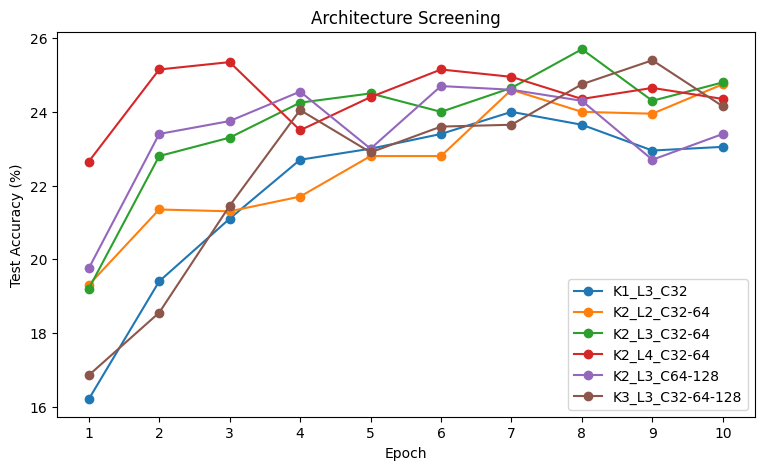

In [9]:
from torch.utils.data import DataLoader, Subset
import copy
import random

SCREEN_TRAIN_SIZE = 10000
SCREEN_TEST_SIZE = 2000
SCREEN_BATCH_SIZE = 256

random.seed(SEED)

train_indices = random.sample(
    range(len(train_dataset)),
    SCREEN_TRAIN_SIZE
)

test_indices = random.sample(
    range(len(test_dataset)),
    SCREEN_TEST_SIZE
)

screen_train = Subset(
    train_dataset,
    train_indices
)

screen_test = Subset(
    test_dataset,
    test_indices
)

screen_train_loader = DataLoader(
    screen_train,
    batch_size=SCREEN_BATCH_SIZE,
    shuffle=True
)

screen_test_loader = DataLoader(
    screen_test,
    batch_size=SCREEN_BATCH_SIZE,
    shuffle=False
)


def run_model(
    model,
    train_loader,
    eval_loader,
    num_epochs,
    learning_rate,
    use_cosine=False
):

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    scheduler = None

    if use_cosine:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=num_epochs,
            eta_min=0.00001
        )

    train_history = []
    test_history = []
    batch_losses = []

    best_test = 0
    best_state = None

    for epoch in range(num_epochs):

        model.train()
        correct = 0
        total = 0

        current_lr = optimizer.param_groups[0]["lr"]

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_accuracy = 100 * correct / total
        train_history.append(train_accuracy)

        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in eval_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                predictions = outputs.argmax(dim=1)

                correct += (
                    predictions == labels
                ).sum().item()

                total += labels.size(0)

        test_accuracy = 100 * correct / total
        test_history.append(test_accuracy)

        if test_accuracy > best_test:
            best_test = test_accuracy
            best_state = {
                key: value.cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"LR: {current_lr:.6f} | "
            f"Train: {train_accuracy:.2f}% | "
            f"Test: {test_accuracy:.2f}%"
        )

        if scheduler is not None:
            scheduler.step()

    if best_state is not None:
        model.load_state_dict(best_state)

    return train_history, test_history, batch_losses


class ScreeningCNN(nn.Module):

    def __init__(self, channels, block_kernels):
        super().__init__()

        self.blocks = nn.ModuleList()
        in_channels = 3

        for out_channels, kernels in zip(
            channels,
            block_kernels
        ):
            self.blocks.append(
                IntermediateBlock(
                    in_channels,
                    out_channels,
                    kernels
                )
            )
            in_channels = out_channels

        self.output_layer = nn.Linear(
            channels[-1],
            10
        )

    def forward(self, x):

        for block in self.blocks:
            x = block(x)

        x = x.mean(dim=(2, 3))
        return self.output_layer(x)


def screening_score(history):
    return np.mean(history[-3:])


architecture_options = {
    "K1_L3_C32": {
        "channels": [32],
        "kernels": [[3, 3, 3]]
    },
    "K2_L2_C32-64": {
        "channels": [32, 64],
        "kernels": [[3, 3], [3, 3]]
    },
    "K2_L3_C32-64": {
        "channels": [32, 64],
        "kernels": [[3, 3, 3], [3, 3, 3]]
    },
    "K2_L4_C32-64": {
        "channels": [32, 64],
        "kernels": [[3, 3, 3, 3], [3, 3, 3, 3]]
    },
    "K2_L3_C64-128": {
        "channels": [64, 128],
        "kernels": [[3, 3, 3], [3, 3, 3]]
    },
    "K3_L3_C32-64-128": {
        "channels": [32, 64, 128],
        "kernels": [[3, 3, 3], [3, 3, 3], [3, 3, 3]]
    }
}

ARCH_EPOCHS = 10
architecture_results = {}

for name, config in architecture_options.items():

    print("\nTesting:", name)
    torch.manual_seed(SEED)

    model = ScreeningCNN(
        channels=config["channels"],
        block_kernels=config["kernels"]
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=ARCH_EPOCHS,
        learning_rate=0.001
    )

    architecture_results[name] = {
        "train": train_history,
        "test": test_history
    }


best_arch_name = max(
    architecture_results,
    key=lambda name: screening_score(
        architecture_results[name]["test"]
    )
)

best_arch_config = architecture_options[
    best_arch_name
]

print("\nARCHITECTURE RESULTS")

for name, result in architecture_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected architecture:")
print(best_arch_name)
print("Channels:", best_arch_config["channels"])
print(
    "Branches per block:",
    len(best_arch_config["kernels"][0])
)

plt.figure(figsize=(9, 5))

for name, result in architecture_results.items():
    plt.plot(
        range(1, ARCH_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Architecture Screening")
plt.xticks(range(1, ARCH_EPOCHS + 1))
plt.legend()
plt.show()


### Architecture Screening Result



The strongest configuration was the 2-block, 3-branch model with 32 → 64 channels. It achieved a final three epoch average test accuracy of 24.93% and a best single-epoch test accuracy of 25.70%.

The 3-block model with 32 → 64 → 128 channels performed similarly, with a final-three average of 24.77%, indicating that increasing depth did not provide a clear improvement at this stage.

The 2-block, 3-branch, 32 → 64 configuration was therefore carried forward to the kernel screening stage.

The plot shows relatively noisy learning which could be attributed to the short training period.



### Kernel Size Screening

The branch count and channel structure are now fixed and carried forward for kernel size screening. Different kernel combinations are compared for 10 epochs using the same screening subset.


Testing kernels: [1, 3, 5]
Epoch 1/10 | LR: 0.001000 | Train: 18.48% | Test: 21.55%
Epoch 2/10 | LR: 0.001000 | Train: 22.06% | Test: 21.75%
Epoch 3/10 | LR: 0.001000 | Train: 23.01% | Test: 21.15%
Epoch 4/10 | LR: 0.001000 | Train: 23.50% | Test: 23.40%
Epoch 5/10 | LR: 0.001000 | Train: 23.54% | Test: 25.05%
Epoch 6/10 | LR: 0.001000 | Train: 23.63% | Test: 24.50%
Epoch 7/10 | LR: 0.001000 | Train: 24.27% | Test: 23.75%
Epoch 8/10 | LR: 0.001000 | Train: 23.77% | Test: 23.20%
Epoch 9/10 | LR: 0.001000 | Train: 23.92% | Test: 23.15%
Epoch 10/10 | LR: 0.001000 | Train: 23.61% | Test: 25.70%

Testing kernels: [1, 3, 7]
Epoch 1/10 | LR: 0.001000 | Train: 18.88% | Test: 21.00%
Epoch 2/10 | LR: 0.001000 | Train: 21.75% | Test: 23.10%
Epoch 3/10 | LR: 0.001000 | Train: 22.42% | Test: 24.90%
Epoch 4/10 | LR: 0.001000 | Train: 23.10% | Test: 25.00%
Epoch 5/10 | LR: 0.001000 | Train: 23.58% | Test: 24.75%
Epoch 6/10 | LR: 0.001000 | Train: 23.84% | Test: 25.30%
Epoch 7/10 | LR: 0.001000 | Tra

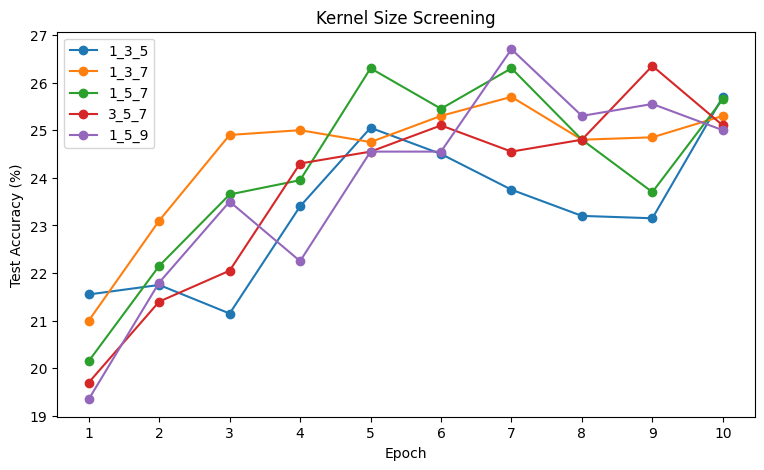

In [10]:
selected_channels = best_arch_config["channels"]
selected_K = len(selected_channels)
selected_L = len(best_arch_config["kernels"][0])

if selected_L == 2:
    kernel_options = {
        "1_3": [1, 3],
        "1_5": [1, 5],
        "3_5": [3, 5],
        "3_7": [3, 7],
        "5_9": [5, 9]
    }

elif selected_L == 3:
    kernel_options = {
        "1_3_5": [1, 3, 5],
        "1_3_7": [1, 3, 7],
        "1_5_7": [1, 5, 7],
        "3_5_7": [3, 5, 7],
        "1_5_9": [1, 5, 9]
    }

elif selected_L == 4:
    kernel_options = {
        "1_3_5_7": [1, 3, 5, 7],
        "1_3_5_9": [1, 3, 5, 9],
        "1_3_7_9": [1, 3, 7, 9],
        "1_5_7_9": [1, 5, 7, 9],
        "3_5_7_9": [3, 5, 7, 9]
    }

else:
    raise ValueError("Unsupported branch count")

KERNEL_EPOCHS = 10
kernel_results = {}

for name, kernels in kernel_options.items():

    print("\nTesting kernels:", kernels)
    torch.manual_seed(SEED)

    block_kernels = [
        kernels.copy()
        for _ in range(selected_K)
    ]

    model = ScreeningCNN(
        channels=selected_channels,
        block_kernels=block_kernels
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=KERNEL_EPOCHS,
        learning_rate=0.001
    )

    kernel_results[name] = {
        "kernels": kernels,
        "train": train_history,
        "test": test_history
    }


best_kernel_name = max(
    kernel_results,
    key=lambda name: screening_score(
        kernel_results[name]["test"]
    )
)

best_kernels = kernel_results[
    best_kernel_name
]["kernels"]

selected_block_kernels = [
    best_kernels.copy()
    for _ in range(selected_K)
]

print("\nKERNEL RESULTS")

for name, result in kernel_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected kernels:", best_kernels)

plt.figure(figsize=(9, 5))

for name, result in kernel_results.items():
    plt.plot(
        range(1, KERNEL_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Kernel Size Screening")
plt.xticks(range(1, KERNEL_EPOCHS + 1))
plt.legend()
plt.show()

### Kernel Size Screening Result

The strongest configuration was the kernel set [3, 5, 7], which achieved a final-three-epoch average test accuracy of 25.42% and a best single-epoch test accuracy of 26.35%.

Although the kernel set [1, 5, 9] reached a slightly higher single-epoch peak of 26.70%, its final-three average was lower at 25.28%. The [3, 5, 7] combination was therefore selected because it gave the most consistent performance at the end of the screening run.

The selected kernel sizes [3, 5, 7] were carried forward to the activation-function experiment.

### Activation Function Screening

The next screening compares activation functions applied after each intermediate block for 10 epochs.


Testing activation: None
Epoch 1/10 | LR: 0.001000 | Train: 16.82% | Test: 19.70%
Epoch 2/10 | LR: 0.001000 | Train: 20.43% | Test: 21.40%
Epoch 3/10 | LR: 0.001000 | Train: 22.08% | Test: 22.05%
Epoch 4/10 | LR: 0.001000 | Train: 22.75% | Test: 24.30%
Epoch 5/10 | LR: 0.001000 | Train: 23.83% | Test: 24.55%
Epoch 6/10 | LR: 0.001000 | Train: 23.82% | Test: 25.10%
Epoch 7/10 | LR: 0.001000 | Train: 23.87% | Test: 24.55%
Epoch 8/10 | LR: 0.001000 | Train: 24.15% | Test: 24.80%
Epoch 9/10 | LR: 0.001000 | Train: 24.84% | Test: 26.35%
Epoch 10/10 | LR: 0.001000 | Train: 24.74% | Test: 25.10%

Testing activation: ReLU
Epoch 1/10 | LR: 0.001000 | Train: 15.39% | Test: 18.80%
Epoch 2/10 | LR: 0.001000 | Train: 22.28% | Test: 23.70%
Epoch 3/10 | LR: 0.001000 | Train: 24.89% | Test: 26.90%
Epoch 4/10 | LR: 0.001000 | Train: 27.85% | Test: 30.45%
Epoch 5/10 | LR: 0.001000 | Train: 29.75% | Test: 29.65%
Epoch 6/10 | LR: 0.001000 | Train: 30.13% | Test: 31.15%
Epoch 7/10 | LR: 0.001000 | Train: 

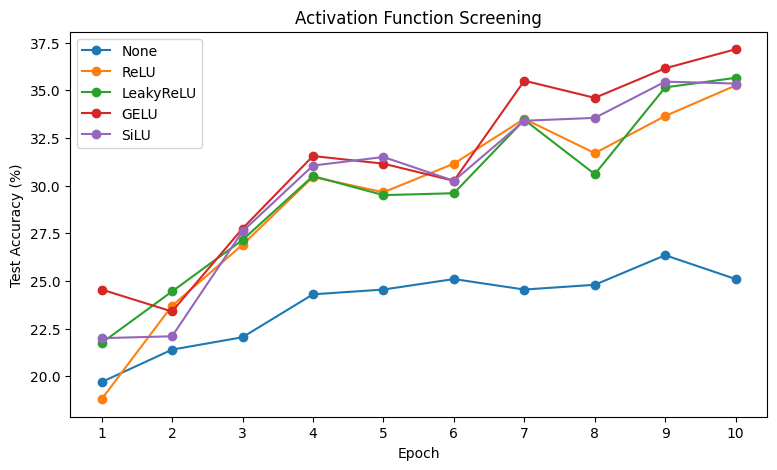

In [11]:
class ActivationCNN(nn.Module):

    def __init__(
        self,
        channels,
        block_kernels,
        activation
    ):
        super().__init__()

        self.blocks = nn.ModuleList()
        self.activation = activation
        in_channels = 3

        for out_channels, kernels in zip(
            channels,
            block_kernels
        ):
            self.blocks.append(
                IntermediateBlock(
                    in_channels,
                    out_channels,
                    kernels
                )
            )
            in_channels = out_channels

        self.output_layer = nn.Linear(
            channels[-1],
            10
        )

    def forward(self, x):

        for block in self.blocks:
            x = block(x)
            x = self.activation(x)

        x = x.mean(dim=(2, 3))
        return self.output_layer(x)


activation_factories = {
    "None": lambda: nn.Identity(),
    "ReLU": lambda: nn.ReLU(),
    "LeakyReLU": lambda: nn.LeakyReLU(0.1),
    "GELU": lambda: nn.GELU(),
    "SiLU": lambda: nn.SiLU()
}

ACTIVATION_EPOCHS = 10
activation_results = {}

for name, make_activation in activation_factories.items():

    print("\nTesting activation:", name)
    torch.manual_seed(SEED)

    model = ActivationCNN(
        channels=selected_channels,
        block_kernels=selected_block_kernels,
        activation=make_activation()
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=ACTIVATION_EPOCHS,
        learning_rate=0.001
    )

    activation_results[name] = {
        "train": train_history,
        "test": test_history
    }


best_activation_name = max(
    activation_results,
    key=lambda name: screening_score(
        activation_results[name]["test"]
    )
)

print("\nACTIVATION RESULTS")

for name, result in activation_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected activation:")
print(best_activation_name)

plt.figure(figsize=(9, 5))

for name, result in activation_results.items():
    plt.plot(
        range(1, ACTIVATION_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Activation Function Screening")
plt.xticks(range(1, ACTIVATION_EPOCHS + 1))
plt.legend()
plt.show()

### Activation Function Screening Result

GELU produced the strongest overall result, with a final three-epoch average test accuracy of 35.97% and a best single-epoch test accuracy of 37.15%. This was higher than SiLU, which achieved a final-three average of 34.78%.

The results also show a clear improvement over using no activation, where the final-three average was only 25.42%. This indicates that introducing a non-linear activation substantially improved the model's representational ability.

GELU was therefore selected and carried forward to the gate activation screening stage.


### Gate Activation Screening

The required fully connected gate is retained. This experiment only changes the activation function applied to the coefficients produced by that gate. Each option is compared for 10 epochs.


Testing gate: Linear
Epoch 1/10 | LR: 0.001000 | Train: 17.18% | Test: 24.55%
Epoch 2/10 | LR: 0.001000 | Train: 23.09% | Test: 23.40%
Epoch 3/10 | LR: 0.001000 | Train: 26.53% | Test: 27.75%
Epoch 4/10 | LR: 0.001000 | Train: 29.79% | Test: 31.55%
Epoch 5/10 | LR: 0.001000 | Train: 31.79% | Test: 31.15%
Epoch 6/10 | LR: 0.001000 | Train: 32.39% | Test: 30.25%
Epoch 7/10 | LR: 0.001000 | Train: 34.52% | Test: 35.50%
Epoch 8/10 | LR: 0.001000 | Train: 36.04% | Test: 34.60%
Epoch 9/10 | LR: 0.001000 | Train: 37.95% | Test: 36.15%
Epoch 10/10 | LR: 0.001000 | Train: 37.81% | Test: 37.15%

Testing gate: ReLU
Epoch 1/10 | LR: 0.001000 | Train: 10.15% | Test: 9.20%
Epoch 2/10 | LR: 0.001000 | Train: 10.26% | Test: 10.20%
Epoch 3/10 | LR: 0.001000 | Train: 10.55% | Test: 10.25%
Epoch 4/10 | LR: 0.001000 | Train: 10.58% | Test: 11.80%
Epoch 5/10 | LR: 0.001000 | Train: 12.73% | Test: 16.15%
Epoch 6/10 | LR: 0.001000 | Train: 14.55% | Test: 17.45%
Epoch 7/10 | LR: 0.001000 | Train: 20.88% | Te

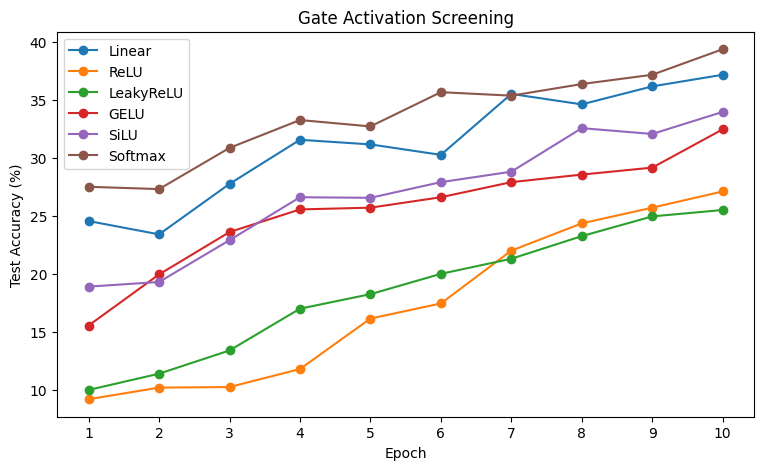

In [12]:
class GateIntermediateBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_sizes,
        gate_activation
    ):
        super().__init__()

        self.num_branches = len(kernel_sizes)

        self.convs = nn.ModuleList([
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=k,
                padding=k // 2
            )
            for k in kernel_sizes
        ])

        self.gate = nn.Linear(
            in_channels,
            self.num_branches
        )

        self.gate_activation = gate_activation

    def forward(self, x):

        channel_means = x.mean(dim=(2, 3))

        weights = self.gate(channel_means)
        weights = self.gate_activation(weights)

        branch_outputs = [
            conv(x)
            for conv in self.convs
        ]

        branch_outputs = torch.stack(
            branch_outputs,
            dim=1
        )

        weights = weights[:, :, None, None, None]

        return (
            weights * branch_outputs
        ).sum(dim=1)


class GateScreeningCNN(nn.Module):

    def __init__(
        self,
        channels,
        block_kernels,
        activation,
        gate_activation,
        pool_size=None,
        use_batchnorm=False
    ):
        super().__init__()

        self.blocks = nn.ModuleList()
        self.norms = nn.ModuleList()
        self.activation = activation
        self.pool = None

        if pool_size is not None:
            self.pool = nn.MaxPool2d(
                kernel_size=pool_size,
                stride=2
            )

        in_channels = 3

        for out_channels, kernels in zip(
            channels,
            block_kernels
        ):
            self.blocks.append(
                GateIntermediateBlock(
                    in_channels,
                    out_channels,
                    kernels,
                    copy.deepcopy(gate_activation)
                )
            )

            if use_batchnorm:
                self.norms.append(
                    nn.BatchNorm2d(out_channels)
                )
            else:
                self.norms.append(nn.Identity())

            in_channels = out_channels

        self.output_layer = nn.Linear(
            channels[-1],
            10
        )

    def forward(self, x):

        for i, block in enumerate(self.blocks):
            x = block(x)
            x = self.activation(x)
            x = self.norms[i](x)

            if (
                self.pool is not None
                and i < len(self.blocks) - 1
            ):
                x = self.pool(x)

        x = x.mean(dim=(2, 3))
        return self.output_layer(x)


gate_activation_factories = {
    "Linear": lambda: nn.Identity(),
    "ReLU": lambda: nn.ReLU(),
    "LeakyReLU": lambda: nn.LeakyReLU(0.1),
    "GELU": lambda: nn.GELU(),
    "SiLU": lambda: nn.SiLU(),
    "Softmax": lambda: nn.Softmax(dim=1)
}

GATE_EPOCHS = 10
gate_results = {}

for name, make_gate_activation in (
    gate_activation_factories.items()
):

    print("\nTesting gate:", name)
    torch.manual_seed(SEED)

    model = GateScreeningCNN(
        channels=selected_channels,
        block_kernels=selected_block_kernels,
        activation=activation_factories[
            best_activation_name
        ](),
        gate_activation=make_gate_activation()
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=GATE_EPOCHS,
        learning_rate=0.001
    )

    gate_results[name] = {
        "train": train_history,
        "test": test_history
    }


best_gate_name = max(
    gate_results,
    key=lambda name: screening_score(
        gate_results[name]["test"]
    )
)

print("\nGATE RESULTS")

for name, result in gate_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected gate:")
print(best_gate_name)

plt.figure(figsize=(9, 5))

for name, result in gate_results.items():
    plt.plot(
        range(1, GATE_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Gate Activation Screening")
plt.xticks(range(1, GATE_EPOCHS + 1))
plt.legend()
plt.show()

### Gate Activation Screening Result

Softmax produced the strongest result, with a final-three-epoch average test accuracy of 37.62% and a best single-epoch test accuracy of 39.35%. This was higher than the linear gate, which achieved a final-three average of 35.97%.

ReLU, LeakyReLU, GELU and SiLU applied to the gate all performed worse than the linear and Softmax alternatives. This suggests that normalising the gate outputs into branch weights using Softmax was more effective than any other activation function for this configuration.

Softmax was therefore selected and carried forward to the depth screening stage.

### Depth Screening

Depth is a central architectural choice, so the number of intermediate blocks is compared for 10 epochs. The selected branch count, kernels, activation and gate remain fixed from the previous screening results.


Testing depth: 1
Epoch 1/10 | LR: 0.001000 | Train: 16.68% | Test: 20.30%
Epoch 2/10 | LR: 0.001000 | Train: 22.42% | Test: 24.05%
Epoch 3/10 | LR: 0.001000 | Train: 25.13% | Test: 25.65%
Epoch 4/10 | LR: 0.001000 | Train: 25.56% | Test: 26.85%
Epoch 5/10 | LR: 0.001000 | Train: 26.30% | Test: 26.90%
Epoch 6/10 | LR: 0.001000 | Train: 27.17% | Test: 27.20%
Epoch 7/10 | LR: 0.001000 | Train: 27.69% | Test: 28.15%
Epoch 8/10 | LR: 0.001000 | Train: 28.30% | Test: 28.05%
Epoch 9/10 | LR: 0.001000 | Train: 29.20% | Test: 28.35%
Epoch 10/10 | LR: 0.001000 | Train: 28.60% | Test: 28.30%

Testing depth: 2
Epoch 1/10 | LR: 0.001000 | Train: 20.35% | Test: 27.50%
Epoch 2/10 | LR: 0.001000 | Train: 26.51% | Test: 27.30%
Epoch 3/10 | LR: 0.001000 | Train: 30.08% | Test: 30.85%
Epoch 4/10 | LR: 0.001000 | Train: 31.83% | Test: 33.25%
Epoch 5/10 | LR: 0.001000 | Train: 33.22% | Test: 32.70%
Epoch 6/10 | LR: 0.001000 | Train: 34.17% | Test: 35.65%
Epoch 7/10 | LR: 0.001000 | Train: 35.03% | Test: 3

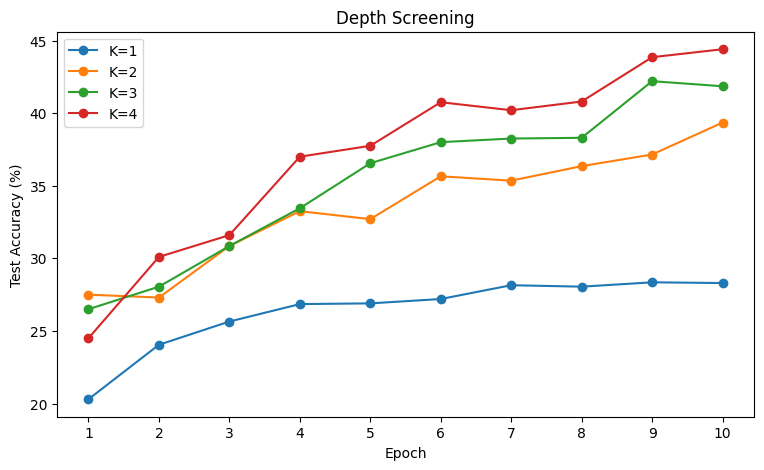

In [13]:
DEPTH_EPOCHS = 10
depth_options = {
    1: [32],
    2: [32, 64],
    3: [32, 64, 64],
    4: [32, 64, 64, 64]
}

depth_results = {}

for K, channels in depth_options.items():

    print("\nTesting depth:", K)
    torch.manual_seed(SEED)

    block_kernels = [
        best_kernels.copy()
        for _ in range(K)
    ]

    model = GateScreeningCNN(
        channels=channels,
        block_kernels=block_kernels,
        activation=activation_factories[
            best_activation_name
        ](),
        gate_activation=gate_activation_factories[
            best_gate_name
        ]()
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=DEPTH_EPOCHS,
        learning_rate=0.001
    )

    depth_results[K] = {
        "channels": channels,
        "train": train_history,
        "test": test_history
    }


best_K = max(
    depth_results,
    key=lambda K: screening_score(
        depth_results[K]["test"]
    )
)

selected_channels = depth_results[
    best_K
]["channels"]

selected_block_kernels = [
    best_kernels.copy()
    for _ in range(best_K)
]

print("\nDEPTH RESULTS")

for K, result in depth_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"K={K}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected depth:", best_K)
print("Channels:", selected_channels)

plt.figure(figsize=(9, 5))

for K, result in depth_results.items():
    plt.plot(
        range(1, DEPTH_EPOCHS + 1),
        result["test"],
        marker="o",
        label=f"K={K}"
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Depth Screening")
plt.xticks(range(1, DEPTH_EPOCHS + 1))
plt.legend()
plt.show()

### Depth Screening Result + additional depth check

The depth screening showed a consistent improvement as the number of intermediate blocks increased, with K=4 achieving the strongest result. Since performance was still improving at the maximum tested depth, an additional K=5 model is evaluated for 10 epochs to determine whether increasing depth further continues to improve performance.

In [14]:
K = 5
channels = [32, 64, 64, 64, 64]

print("\nTesting additional depth: K=5")
torch.manual_seed(SEED)

block_kernels = [
    best_kernels.copy()
    for _ in range(K)
]

model = GateScreeningCNN(
    channels=channels,
    block_kernels=block_kernels,
    activation=activation_factories[
        best_activation_name
    ](),
    gate_activation=gate_activation_factories[
        best_gate_name
    ]()
)

train_history, test_history, _ = run_model(
    model,
    screen_train_loader,
    screen_test_loader,
    num_epochs=10,
    learning_rate=0.001
)

depth_results[K] = {
    "channels": channels,
    "train": train_history,
    "test": test_history
}

score = screening_score(test_history)
best = max(test_history)

print(
    f"\nK=5: Final-3 Average = {score:.2f}% | "
    f"Best = {best:.2f}%"
)

best_K = max(
    depth_results,
    key=lambda K: screening_score(
        depth_results[K]["test"]
    )
)

selected_channels = depth_results[
    best_K
]["channels"]

selected_block_kernels = [
    best_kernels.copy()
    for _ in range(best_K)
]

print("\nUpdated selected depth:", best_K)
print("Channels:", selected_channels)


Testing additional depth: K=5
Epoch 1/10 | LR: 0.001000 | Train: 18.20% | Test: 23.30%
Epoch 2/10 | LR: 0.001000 | Train: 25.74% | Test: 30.60%
Epoch 3/10 | LR: 0.001000 | Train: 29.11% | Test: 29.80%
Epoch 4/10 | LR: 0.001000 | Train: 33.56% | Test: 35.45%
Epoch 5/10 | LR: 0.001000 | Train: 35.59% | Test: 36.45%
Epoch 6/10 | LR: 0.001000 | Train: 38.00% | Test: 38.70%
Epoch 7/10 | LR: 0.001000 | Train: 39.50% | Test: 41.10%
Epoch 8/10 | LR: 0.001000 | Train: 42.54% | Test: 42.20%
Epoch 9/10 | LR: 0.001000 | Train: 45.00% | Test: 39.65%
Epoch 10/10 | LR: 0.001000 | Train: 45.59% | Test: 45.10%

K=5: Final-3 Average = 42.32% | Best = 45.10%

Updated selected depth: 4
Channels: [32, 64, 64, 64]


Although K=5 performed well, it was still outperformed by K=4. This suggests that adding an additional block did not provide a further improvement under the current screening conditions, so K=4 was kept.

### Width Screening

After selecting depth, three different channel-width configurations are re-evaluated for 10 epochs. The number of blocks and all other architectural choices remain fixed.


Testing width: Base [32, 64, 64, 64]
Epoch 1/10 | LR: 0.001000 | Train: 19.88% | Test: 24.50%
Epoch 2/10 | LR: 0.001000 | Train: 27.54% | Test: 30.10%
Epoch 3/10 | LR: 0.001000 | Train: 30.94% | Test: 31.60%
Epoch 4/10 | LR: 0.001000 | Train: 35.62% | Test: 37.00%
Epoch 5/10 | LR: 0.001000 | Train: 37.61% | Test: 37.75%
Epoch 6/10 | LR: 0.001000 | Train: 39.01% | Test: 40.75%
Epoch 7/10 | LR: 0.001000 | Train: 42.43% | Test: 40.20%
Epoch 8/10 | LR: 0.001000 | Train: 43.61% | Test: 40.80%
Epoch 9/10 | LR: 0.001000 | Train: 46.19% | Test: 43.85%
Epoch 10/10 | LR: 0.001000 | Train: 47.71% | Test: 44.40%

Testing width: 1.5x [48, 96, 96, 96]
Epoch 1/10 | LR: 0.001000 | Train: 19.75% | Test: 26.15%
Epoch 2/10 | LR: 0.001000 | Train: 28.28% | Test: 30.60%
Epoch 3/10 | LR: 0.001000 | Train: 32.61% | Test: 34.05%
Epoch 4/10 | LR: 0.001000 | Train: 36.44% | Test: 31.50%
Epoch 5/10 | LR: 0.001000 | Train: 37.25% | Test: 41.65%
Epoch 6/10 | LR: 0.001000 | Train: 40.23% | Test: 40.70%
Epoch 7/10 

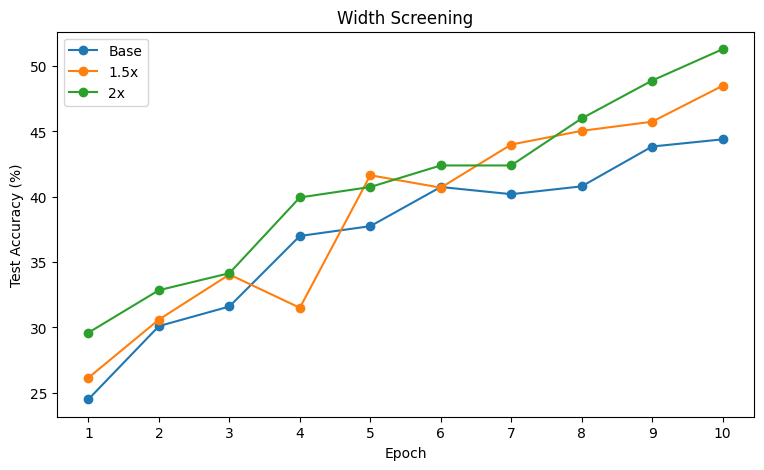

In [15]:
WIDTH_EPOCHS = 10
width_options = {
    "Base": selected_channels.copy(),
    "1.5x": [
        int(channel * 1.5)
        for channel in selected_channels
    ],
    "2x": [
        channel * 2
        for channel in selected_channels
    ]
}

width_results = {}

for name, channels in width_options.items():

    print("\nTesting width:", name, channels)
    torch.manual_seed(SEED)

    block_kernels = [
        best_kernels.copy()
        for _ in channels
    ]

    model = GateScreeningCNN(
        channels=channels,
        block_kernels=block_kernels,
        activation=activation_factories[
            best_activation_name
        ](),
        gate_activation=gate_activation_factories[
            best_gate_name
        ]()
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=WIDTH_EPOCHS,
        learning_rate=0.001
    )

    width_results[name] = {
        "channels": channels,
        "train": train_history,
        "test": test_history
    }


best_width_name = max(
    width_results,
    key=lambda name: screening_score(
        width_results[name]["test"]
    )
)

selected_channels = width_results[
    best_width_name
]["channels"]

selected_block_kernels = [
    best_kernels.copy()
    for _ in selected_channels
]

print("\nWIDTH RESULTS")

for name, result in width_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name} {result['channels']}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected width:")
print(best_width_name, selected_channels)

plt.figure(figsize=(9, 5))

for name, result in width_results.items():
    plt.plot(
        range(1, WIDTH_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Width Screening")
plt.xticks(range(1, WIDTH_EPOCHS + 1))
plt.legend()
plt.show()

### Width Screening Result

Increasing the channel width improved performance consistently. The base configuration achieved a final-three-epoch average test accuracy of 43.02%, while the 1.5x configuration increased this to 46.43%.

The strongest result was produced by the 2x configuration, using channels [64, 128, 128, 128]. This achieved a final-three average test accuracy of 48.73% and a best single-epoch test accuracy of 51.30%.

The 2x width configuration was therefore selected and carried forward to the pooling experiment.

### Pooling Screening
The next step involved screening Max Pooling between blocks. No pooling, 2×2 max pooling and 3×3 max pooling were compared over 10 epochs. Max Pooling reduces the spatial size of the feature maps by keeping the maximum value within each local region, which lowers computation and can help retain the strongest detected features.


Testing: No pooling
Epoch 1/10 | LR: 0.001000 | Train: 22.49% | Test: 29.60%
Epoch 2/10 | LR: 0.001000 | Train: 30.00% | Test: 32.85%
Epoch 3/10 | LR: 0.001000 | Train: 35.31% | Test: 34.15%
Epoch 4/10 | LR: 0.001000 | Train: 37.27% | Test: 39.95%
Epoch 5/10 | LR: 0.001000 | Train: 41.87% | Test: 40.75%
Epoch 6/10 | LR: 0.001000 | Train: 44.18% | Test: 42.40%
Epoch 7/10 | LR: 0.001000 | Train: 47.09% | Test: 42.40%
Epoch 8/10 | LR: 0.001000 | Train: 48.12% | Test: 46.00%
Epoch 9/10 | LR: 0.001000 | Train: 50.66% | Test: 48.90%
Epoch 10/10 | LR: 0.001000 | Train: 53.53% | Test: 51.30%

Testing: MaxPool 2x2
Epoch 1/10 | LR: 0.001000 | Train: 24.14% | Test: 33.60%
Epoch 2/10 | LR: 0.001000 | Train: 35.08% | Test: 39.30%
Epoch 3/10 | LR: 0.001000 | Train: 40.27% | Test: 44.85%
Epoch 4/10 | LR: 0.001000 | Train: 44.72% | Test: 48.85%
Epoch 5/10 | LR: 0.001000 | Train: 49.36% | Test: 50.00%
Epoch 6/10 | LR: 0.001000 | Train: 53.58% | Test: 50.70%
Epoch 7/10 | LR: 0.001000 | Train: 55.77% | 

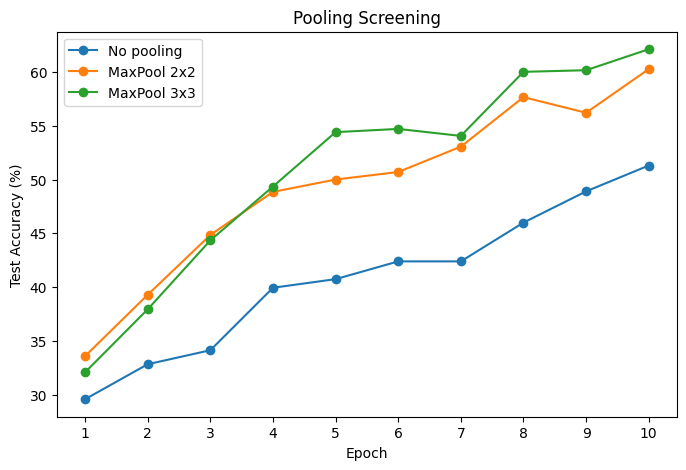

In [16]:
POOL_EPOCHS = 10
pooling_options = {
    "No pooling": None,
    "MaxPool 2x2": 2,
    "MaxPool 3x3": 3
}

pooling_results = {}

for name, pool_size in pooling_options.items():

    print("\nTesting:", name)
    torch.manual_seed(SEED)

    model = GateScreeningCNN(
        channels=selected_channels,
        block_kernels=selected_block_kernels,
        activation=activation_factories[
            best_activation_name
        ](),
        gate_activation=gate_activation_factories[
            best_gate_name
        ](),
        pool_size=pool_size
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=POOL_EPOCHS,
        learning_rate=0.001
    )

    pooling_results[name] = {
        "pool_size": pool_size,
        "train": train_history,
        "test": test_history
    }


best_pool_name = max(
    pooling_results,
    key=lambda name: screening_score(
        pooling_results[name]["test"]
    )
)

best_pool_size = pooling_results[
    best_pool_name
]["pool_size"]

print("\nPOOLING RESULTS")

for name, result in pooling_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected pooling:")
print(best_pool_name)

plt.figure(figsize=(8, 5))

for name, result in pooling_results.items():
    plt.plot(
        range(1, POOL_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Pooling Screening")
plt.xticks(range(1, POOL_EPOCHS + 1))
plt.legend()
plt.show()

### Pooling Screening Result

Pooling produced a substantial improvement in performance compared with using no pooling.

The model without pooling achieved a final-three-epoch average test accuracy of 48.73%. Adding 2x2 max pooling increased this to 58.03%, while 3x3 max pooling achieved the strongest result at 60.75%.

The 3x3 pooling configuration also reached the highest single-epoch test accuracy of 62.10%. This indicates that stronger spatial downsampling was beneficial for the selected architecture.

MaxPool 3x3 was therefore selected and carried forward to the learning-rate screening stage.


### Learning Rate Screening

 Learning rates of 0.001, 0.002 and 0.003 are explored next over 10 epochs using the same screening subset.


Testing learning rate: 0.001
Epoch 1/10 | LR: 0.001000 | Train: 22.74% | Test: 32.10%
Epoch 2/10 | LR: 0.001000 | Train: 35.02% | Test: 37.95%
Epoch 3/10 | LR: 0.001000 | Train: 42.59% | Test: 44.35%
Epoch 4/10 | LR: 0.001000 | Train: 47.57% | Test: 49.35%
Epoch 5/10 | LR: 0.001000 | Train: 52.26% | Test: 54.40%
Epoch 6/10 | LR: 0.001000 | Train: 56.89% | Test: 54.70%
Epoch 7/10 | LR: 0.001000 | Train: 59.40% | Test: 54.05%
Epoch 8/10 | LR: 0.001000 | Train: 59.72% | Test: 60.00%
Epoch 9/10 | LR: 0.001000 | Train: 63.65% | Test: 60.15%
Epoch 10/10 | LR: 0.001000 | Train: 66.35% | Test: 62.10%

Testing learning rate: 0.002
Epoch 1/10 | LR: 0.002000 | Train: 24.88% | Test: 34.75%
Epoch 2/10 | LR: 0.002000 | Train: 37.84% | Test: 35.20%
Epoch 3/10 | LR: 0.002000 | Train: 44.56% | Test: 48.55%
Epoch 4/10 | LR: 0.002000 | Train: 49.88% | Test: 52.60%
Epoch 5/10 | LR: 0.002000 | Train: 54.11% | Test: 53.90%
Epoch 6/10 | LR: 0.002000 | Train: 57.61% | Test: 52.15%
Epoch 7/10 | LR: 0.002000 |

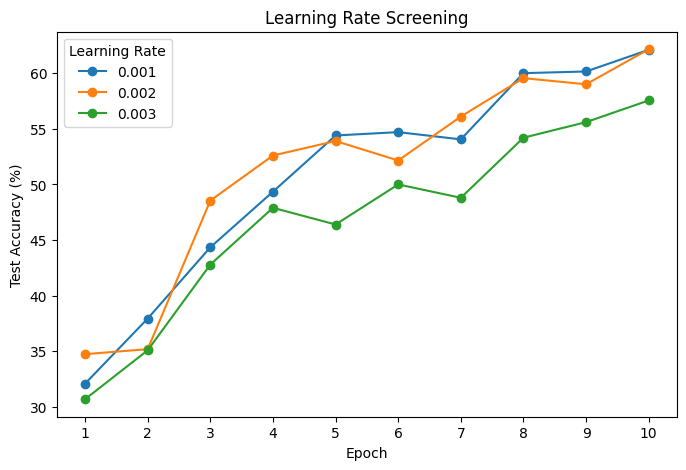

In [17]:
class OptimalBlockModel(GateScreeningCNN):

    def __init__(self, use_batchnorm=False):
        super().__init__(
            channels=selected_channels,
            block_kernels=selected_block_kernels,
            activation=activation_factories[
                best_activation_name
            ](),
            gate_activation=gate_activation_factories[
                best_gate_name
            ](),
            pool_size=best_pool_size,
            use_batchnorm=use_batchnorm
        )


LR_EPOCHS = 10
learning_rates = [0.001, 0.002, 0.003]
lr_results = {}

for lr in learning_rates:

    print("\nTesting learning rate:", lr)
    torch.manual_seed(SEED)

    model = OptimalBlockModel(
        use_batchnorm=False
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=LR_EPOCHS,
        learning_rate=lr
    )

    lr_results[lr] = {
        "train": train_history,
        "test": test_history
    }


best_learning_rate = max(
    lr_results,
    key=lambda lr: screening_score(
        lr_results[lr]["test"]
    )
)

print("\nLEARNING RATE RESULTS")

for lr, result in lr_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{lr}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected learning rate:")
print(best_learning_rate)

plt.figure(figsize=(8, 5))

for lr, result in lr_results.items():
    plt.plot(
        range(1, LR_EPOCHS + 1),
        result["test"],
        marker="o",
        label=str(lr)
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Learning Rate Screening")
plt.xticks(range(1, LR_EPOCHS + 1))
plt.legend(title="Learning Rate")
plt.show()

### Learning Rate Screening Result

Learning rates 0.001 and 0.002 produced very similar results. A learning rate of 0.001 achieved the strongest final three epoch average test accuracy of 60.75%, while 0.002 achieved 60.23%.

Although 0.002 reached a slightly higher single-epoch peak of 62.15% compared with 62.10% for 0.001, the difference was negligible. Based on the predefined best of last three epochs selection criterion, 0.001 was selected.

The higher learning rate of 0.003 performed noticeably worse, with a final-three average of 55.78%.

The learning rate 0.001 was therefore carried forward to the Batch Normalisation experiment.

### Batch Normalisation Screening

Batch Normalisation is compared against the selected architecture without Batch Normalisation for 10 epochs. All other settings are kept fixed.


Testing: No BatchNorm
Epoch 1/10 | LR: 0.001000 | Train: 22.74% | Test: 32.10%
Epoch 2/10 | LR: 0.001000 | Train: 35.02% | Test: 37.95%
Epoch 3/10 | LR: 0.001000 | Train: 42.59% | Test: 44.35%
Epoch 4/10 | LR: 0.001000 | Train: 47.57% | Test: 49.35%
Epoch 5/10 | LR: 0.001000 | Train: 52.26% | Test: 54.40%
Epoch 6/10 | LR: 0.001000 | Train: 56.89% | Test: 54.70%
Epoch 7/10 | LR: 0.001000 | Train: 59.40% | Test: 54.05%
Epoch 8/10 | LR: 0.001000 | Train: 59.72% | Test: 60.00%
Epoch 9/10 | LR: 0.001000 | Train: 63.65% | Test: 60.15%
Epoch 10/10 | LR: 0.001000 | Train: 66.35% | Test: 62.10%

Testing: BatchNorm
Epoch 1/10 | LR: 0.001000 | Train: 33.86% | Test: 41.70%
Epoch 2/10 | LR: 0.001000 | Train: 45.16% | Test: 44.80%
Epoch 3/10 | LR: 0.001000 | Train: 51.23% | Test: 51.30%
Epoch 4/10 | LR: 0.001000 | Train: 56.64% | Test: 57.25%
Epoch 5/10 | LR: 0.001000 | Train: 60.13% | Test: 53.10%
Epoch 6/10 | LR: 0.001000 | Train: 63.84% | Test: 56.05%
Epoch 7/10 | LR: 0.001000 | Train: 65.72% | 

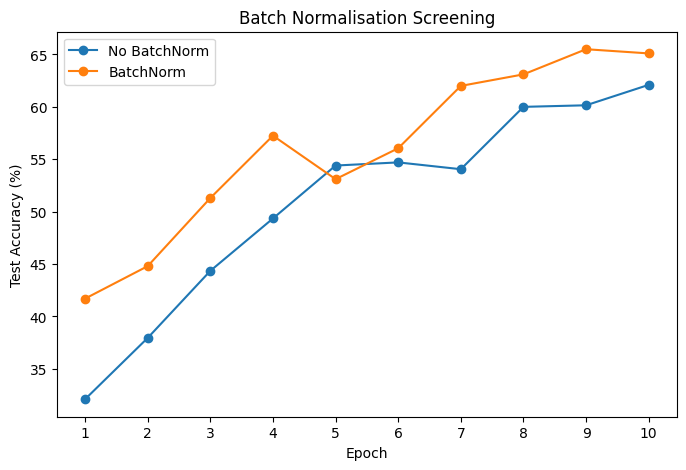

In [18]:
BN_EPOCHS = 10
batchnorm_options = {
    "No BatchNorm": False,
    "BatchNorm": True
}

batchnorm_results = {}

for name, use_bn in batchnorm_options.items():

    print("\nTesting:", name)
    torch.manual_seed(SEED)

    model = OptimalBlockModel(
        use_batchnorm=use_bn
    )

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=BN_EPOCHS,
        learning_rate=best_learning_rate
    )

    batchnorm_results[name] = {
        "use_batchnorm": use_bn,
        "train": train_history,
        "test": test_history
    }


best_batchnorm_name = max(
    batchnorm_results,
    key=lambda name: screening_score(
        batchnorm_results[name]["test"]
    )
)

best_use_batchnorm = batchnorm_results[
    best_batchnorm_name
]["use_batchnorm"]

print("\nBATCH NORMALISATION RESULTS")

for name, result in batchnorm_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected option:")
print(best_batchnorm_name)

plt.figure(figsize=(8, 5))

for name, result in batchnorm_results.items():
    plt.plot(
        range(1, BN_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Batch Normalisation Screening")
plt.xticks(range(1, BN_EPOCHS + 1))
plt.legend()
plt.show()

### Batch Normalisation Screening Result

Batch Normalisation improved the selected model over the 10-epoch screening run.

Without BatchNorm, the model achieved a final-three-epoch average test accuracy of 60.75% and a best single-epoch accuracy of 62.10%.

With BatchNorm, the final-three average increased to 64.57%, while the best single-epoch test accuracy increased to 65.50%.

The improvement was consistent across the later epochs, so BatchNorm was selected and carried forward to the learning rate scheduler experiment.

### Learning Rate Scheduler Screening

The selected model is compared using a constant learning rate and cosine learning rate scheduler. This comparison is also run for 10 epochs.


Testing: Constant LR
Epoch 1/10 | LR: 0.001000 | Train: 33.86% | Test: 41.70%
Epoch 2/10 | LR: 0.001000 | Train: 45.16% | Test: 44.80%
Epoch 3/10 | LR: 0.001000 | Train: 51.23% | Test: 51.30%
Epoch 4/10 | LR: 0.001000 | Train: 56.64% | Test: 57.25%
Epoch 5/10 | LR: 0.001000 | Train: 60.13% | Test: 53.10%
Epoch 6/10 | LR: 0.001000 | Train: 63.84% | Test: 56.05%
Epoch 7/10 | LR: 0.001000 | Train: 65.72% | Test: 62.00%
Epoch 8/10 | LR: 0.001000 | Train: 67.39% | Test: 63.10%
Epoch 9/10 | LR: 0.001000 | Train: 70.43% | Test: 65.50%
Epoch 10/10 | LR: 0.001000 | Train: 71.55% | Test: 65.10%

Testing: Cosine LR
Epoch 1/10 | LR: 0.001000 | Train: 33.86% | Test: 41.70%
Epoch 2/10 | LR: 0.000976 | Train: 45.21% | Test: 44.35%
Epoch 3/10 | LR: 0.000905 | Train: 51.13% | Test: 52.35%
Epoch 4/10 | LR: 0.000796 | Train: 57.31% | Test: 56.70%
Epoch 5/10 | LR: 0.000658 | Train: 61.43% | Test: 56.70%
Epoch 6/10 | LR: 0.000505 | Train: 66.11% | Test: 59.20%
Epoch 7/10 | LR: 0.000352 | Train: 68.29% | T

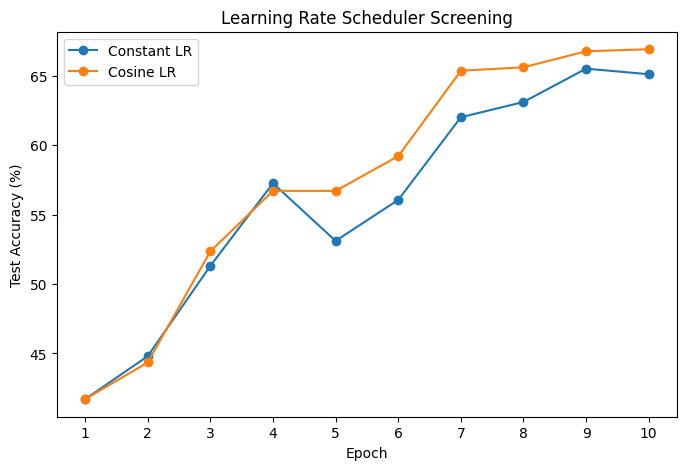

In [19]:
class OptimalBlockModel(GateScreeningCNN):

    def __init__(self):
        super().__init__(
            channels=selected_channels,
            block_kernels=selected_block_kernels,
            activation=activation_factories[
                best_activation_name
            ](),
            gate_activation=gate_activation_factories[
                best_gate_name
            ](),
            pool_size=best_pool_size,
            use_batchnorm=best_use_batchnorm
        )


SCHEDULER_EPOCHS = 10
scheduler_options = {
    "Constant LR": False,
    "Cosine LR": True
}

scheduler_results = {}

for name, use_cosine in scheduler_options.items():

    print("\nTesting:", name)
    torch.manual_seed(SEED)

    model = OptimalBlockModel()

    train_history, test_history, _ = run_model(
        model,
        screen_train_loader,
        screen_test_loader,
        num_epochs=SCHEDULER_EPOCHS,
        learning_rate=best_learning_rate,
        use_cosine=use_cosine
    )

    scheduler_results[name] = {
        "use_cosine": use_cosine,
        "train": train_history,
        "test": test_history
    }


best_scheduler_name = max(
    scheduler_results,
    key=lambda name: screening_score(
        scheduler_results[name]["test"]
    )
)

best_use_cosine = scheduler_results[
    best_scheduler_name
]["use_cosine"]

print("\nSCHEDULER RESULTS")

for name, result in scheduler_results.items():
    score = screening_score(result["test"])
    best = max(result["test"])

    print(
        f"{name}: "
        f"Final-3 Average = {score:.2f}% | "
        f"Best = {best:.2f}%"
    )

print("\nSelected scheduler:")
print(best_scheduler_name)

plt.figure(figsize=(8, 5))

for name, result in scheduler_results.items():
    plt.plot(
        range(1, SCHEDULER_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Learning Rate Scheduler Screening")
plt.xticks(range(1, SCHEDULER_EPOCHS + 1))
plt.legend()
plt.show()

### Learning Rate Scheduler Screening Result

The constant learning rate achieved a final-three-epoch average test accuracy of 64.57% and a best single-epoch accuracy of 65.50%.

The cosine learning rate scheduler performed better, reaching a final-three average of 66.42% and a best single-epoch test accuracy of 66.90%. Performance also continued to improve as the learning rate decreased during the later epochs.

Cosine therefore seems suitable for future longer training runs.

## Selected Architecture: 20-Epoch Full-Dataset Check

The selected architecture and optimisation settings are now trained on the full CIFAR-10 training set for 20 epochs. This provides a stronger checkpoint before testing data augmentation.

Epoch 1/20 | LR: 0.001000 | Train: 51.70% | Test: 62.45%
Epoch 2/20 | LR: 0.000994 | Train: 69.43% | Test: 70.54%
Epoch 3/20 | LR: 0.000976 | Train: 75.33% | Test: 76.32%
Epoch 4/20 | LR: 0.000946 | Train: 78.69% | Test: 79.41%
Epoch 5/20 | LR: 0.000905 | Train: 81.35% | Test: 80.30%
Epoch 6/20 | LR: 0.000855 | Train: 82.98% | Test: 81.75%
Epoch 7/20 | LR: 0.000796 | Train: 84.58% | Test: 81.52%
Epoch 8/20 | LR: 0.000730 | Train: 85.98% | Test: 82.63%
Epoch 9/20 | LR: 0.000658 | Train: 87.45% | Test: 83.19%
Epoch 10/20 | LR: 0.000582 | Train: 88.64% | Test: 84.00%
Epoch 11/20 | LR: 0.000505 | Train: 89.87% | Test: 84.20%
Epoch 12/20 | LR: 0.000428 | Train: 90.76% | Test: 84.71%
Epoch 13/20 | LR: 0.000352 | Train: 91.79% | Test: 85.29%
Epoch 14/20 | LR: 0.000280 | Train: 92.75% | Test: 85.25%
Epoch 15/20 | LR: 0.000214 | Train: 93.71% | Test: 85.64%
Epoch 16/20 | LR: 0.000155 | Train: 94.40% | Test: 85.80%
Epoch 17/20 | LR: 0.000105 | Train: 94.86% | Test: 85.92%
Epoch 18/20 | LR: 0.000

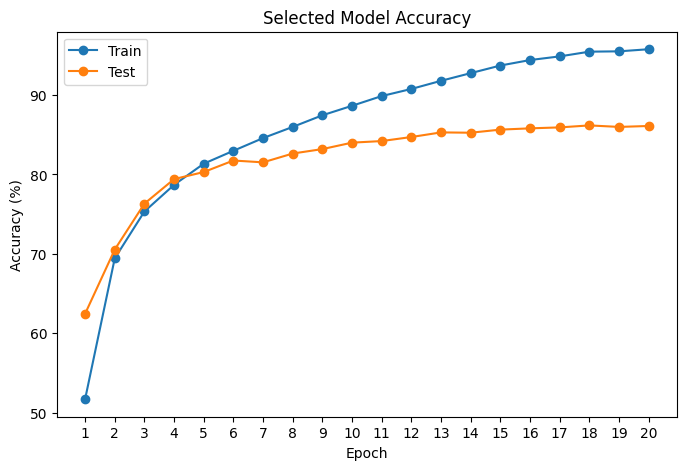

In [20]:
torch.manual_seed(SEED)

selected_model = OptimalBlockModel()

selected_train_acc, selected_test_acc, selected_batch_losses = run_model(
    selected_model,
    train_loader,
    test_loader,
    num_epochs=20,
    learning_rate=best_learning_rate,
    use_cosine=best_use_cosine
)

selected_best_epoch = (
    selected_test_acc.index(
        max(selected_test_acc)
    ) + 1
)

print("\n20-EPOCH MODEL RESULT")
print(
    f"Best Test = {max(selected_test_acc):.2f}% | "
    f"Epoch = {selected_best_epoch}"
)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 21),
    selected_train_acc,
    marker="o",
    label="Train"
)
plt.plot(
    range(1, 21),
    selected_test_acc,
    marker="o",
    label="Test"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Selected Model Accuracy")
plt.xticks(range(1, 21))
plt.legend()
plt.show()

### 20-Epoch Full-Dataset Result

Performance improved steadily throughout training, reaching a best test accuracy of 86.17% at epoch 18. By epoch 20, training accuracy had reached 95.76% while test accuracy remained at 86.10%.

This shows that the selected architecture and optimisation settings generalised substantially better than the earlier screening models. However the roughly 10% train-test gap in the later epochs suggest some overfitting as training progresses.

If overfitting were to continue then some reduction techniques such as early-stopping could be explored. However, for now the current model architecture will remain fixed as stronger data augmentation is
explored as a way of improving generalisation without changing the required network structure.

## Data Augmentation

For the data augmentation screening, the existing RandomCrop and horizontal-flip preprocessing is compared with Random Erasing and AutoAugment using the CIFAR-10 policy. Each option is trained for 15 epochs on the full training set.

AutoAugment was something I came across in relevant literature on CIFAR-10 [5]. It is a data augmentation method which automatically searches for effective data-augmentation policies rather than manually selecting individual transformations. Each learned policy contains several sub-policies consisting of image transformations such as rotation, translation and shearing, together with probabilities and transformation magnitudes.

In this project, the augmentation policy itself was not learned from scratch, since reproducing the AutoAugment search process would require substantial additional computation. Instead, the predefined CIFAR-10 AutoAugment policy available in torchvision was used. TorchVision provides this learned CIFAR-10 policy directly through `transforms.AutoAugmentPolicy.CIFAR10`.

Cutout was also inspired by relevant literature. DeVries and Taylor [4] proposed randomly masking rectangular regions of training images so that the model cannot rely too strongly on a small set of local features. In this project, a Cutout-style approach was implemented using TorchVision’s RandomErasing, with a probability of 0.5 and an erased area between 2% and 25% of the image. This provided a simple approximation of the Cutout principle without requiring a separate implementation.


Testing: Current
Epoch 1/15 | LR: 0.001000 | Train: 51.70% | Test: 62.45%
Epoch 2/15 | LR: 0.000989 | Train: 69.39% | Test: 71.11%
Epoch 3/15 | LR: 0.000957 | Train: 75.27% | Test: 76.91%
Epoch 4/15 | LR: 0.000905 | Train: 78.74% | Test: 78.02%
Epoch 5/15 | LR: 0.000836 | Train: 81.38% | Test: 80.80%
Epoch 6/15 | LR: 0.000752 | Train: 83.36% | Test: 81.80%
Epoch 7/15 | LR: 0.000658 | Train: 84.91% | Test: 82.17%
Epoch 8/15 | LR: 0.000557 | Train: 86.66% | Test: 83.29%
Epoch 9/15 | LR: 0.000453 | Train: 88.30% | Test: 84.06%
Epoch 10/15 | LR: 0.000352 | Train: 89.54% | Test: 84.24%
Epoch 11/15 | LR: 0.000258 | Train: 90.74% | Test: 85.02%
Epoch 12/15 | LR: 0.000174 | Train: 91.93% | Test: 85.27%
Epoch 13/15 | LR: 0.000105 | Train: 92.63% | Test: 85.82%
Epoch 14/15 | LR: 0.000053 | Train: 93.21% | Test: 85.98%
Epoch 15/15 | LR: 0.000021 | Train: 93.59% | Test: 86.02%

Testing: Cutout
Epoch 1/15 | LR: 0.001000 | Train: 49.19% | Test: 60.70%
Epoch 2/15 | LR: 0.000989 | Train: 64.81% | Tes

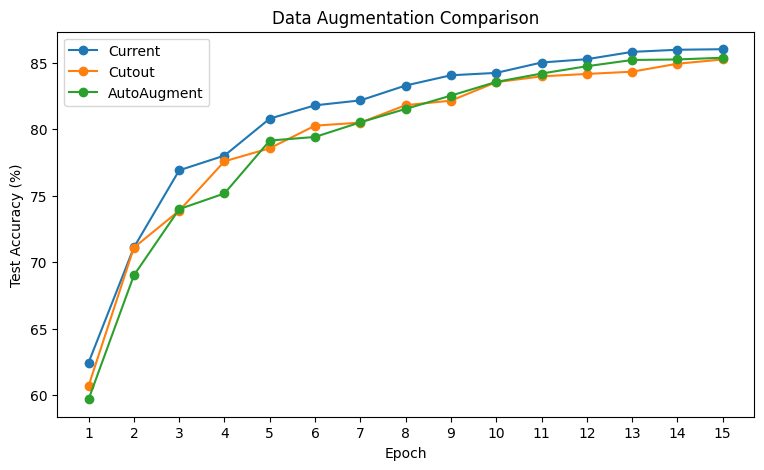

In [21]:
baseline_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

cutout_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(
        p=0.5,
        scale=(0.02, 0.25)
    )
])

autoaugment_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.AutoAugment(
        policy=transforms.AutoAugmentPolicy.CIFAR10
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

AUG_EPOCHS = 15

augmentation_options = {
    "Current": baseline_transform,
    "Cutout": cutout_transform,
    "AutoAugment": autoaugment_transform
}

augmentation_results = {}

for name, transform in augmentation_options.items():

    print("\nTesting:", name)

    train_dataset_aug = datasets.CIFAR10(
        root=str(DATA_DIR),
        train=True,
        download=False,
        transform=transform
    )

    train_loader_aug = DataLoader(
        train_dataset_aug,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    torch.manual_seed(SEED)

    model = OptimalBlockModel()

    train_history, test_history, _ = run_model(
        model,
        train_loader_aug,
        test_loader,
        num_epochs=AUG_EPOCHS,
        learning_rate=best_learning_rate,
        use_cosine=best_use_cosine
    )

    augmentation_results[name] = {
        "transform": transform,
        "train": train_history,
        "test": test_history
    }


best_augmentation_name = max(
    augmentation_results,
    key=lambda name: max(
        augmentation_results[name]["test"]
    )
)

best_augmentation_transform = augmentation_results[
    best_augmentation_name
]["transform"]

print("\nAUGMENTATION RESULTS")

for name, result in augmentation_results.items():
    best_epoch = (
        result["test"].index(
            max(result["test"])
        ) + 1
    )

    print(
        f"{name}: "
        f"Best Test = {max(result['test']):.2f}% | "
        f"Epoch = {best_epoch}"
    )

print("\nSelected augmentation:")
print(best_augmentation_name)

plt.figure(figsize=(9, 5))

for name, result in augmentation_results.items():
    plt.plot(
        range(1, AUG_EPOCHS + 1),
        result["test"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Data Augmentation Comparison")
plt.xticks(range(1, AUG_EPOCHS + 1))
plt.legend()
plt.show()

### Data Augmentation Result

The current augmentation approach achieved the highest test accuracy of 86.02%. AutoAugment reached 85.38%, while Cutout achieved 85.25%.

Although the existing augmentation produced the highest accuracy, it also showed a clearer gap between training and test performance, reaching 93.59% training accuracy compared with 86.02% test accuracy at epoch 15. This is a sign of overfitting.

On the other hand, AutoAugment behaved differently. Its training accuracy was much lower at 81.44%, while test accuracy reached 85.38%. This is expected because AutoAugment applies stronger transformations to the training images, making the training task more difficult while also providing stronger regularisation.

AutoAugment was also still improving at the end of the 15-epoch run without signs of overfitting. This suggested that a longer training period may be required for the model to benefit fully from the stronger augmentation.

For this reason, the existing augmentation and AutoAugment were selected for an additional 30-epoch comparison using the same architecture, optimiser and cosine learning-rate schedule. Cutout was not carried forward because it performed below both alternatives in the initial screening.

In [22]:
LONG_AUG_EPOCHS = 30

long_aug_options = {
    "Current": baseline_transform,
    "AutoAugment": autoaugment_transform
}

long_aug_results = {}

for name, transform in long_aug_options.items():

    print("\nTesting:", name)

    torch.manual_seed(SEED)

    train_dataset_aug = datasets.CIFAR10(
        root=str(DATA_DIR),
        train=True,
        download=False,
        transform=transform
    )

    train_loader_aug = DataLoader(
        train_dataset_aug,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    model = OptimalBlockModel()

    train_history, test_history, _ = run_model(
        model,
        train_loader_aug,
        test_loader,
        num_epochs=LONG_AUG_EPOCHS,
        learning_rate=best_learning_rate,
        use_cosine=True
    )

    long_aug_results[name] = {
        "train": train_history,
        "test": test_history
    }


print("\n30-EPOCH AUGMENTATION RESULTS")

for name, result in long_aug_results.items():
    best_epoch = result["test"].index(
        max(result["test"])
    ) + 1

    print(
        f"{name}: "
        f"Best Test = {max(result['test']):.2f}% | "
        f"Epoch = {best_epoch}"
    )

best_long_aug = max(
    long_aug_results,
    key=lambda name: max(
        long_aug_results[name]["test"]
    )
)

print("\nSelected augmentation:")
print(best_long_aug)


Testing: Current
Epoch 1/30 | LR: 0.001000 | Train: 51.70% | Test: 62.45%
Epoch 2/30 | LR: 0.000997 | Train: 69.39% | Test: 70.64%
Epoch 3/30 | LR: 0.000989 | Train: 75.06% | Test: 76.27%
Epoch 4/30 | LR: 0.000976 | Train: 78.57% | Test: 77.64%
Epoch 5/30 | LR: 0.000957 | Train: 80.95% | Test: 80.38%
Epoch 6/30 | LR: 0.000934 | Train: 82.62% | Test: 81.93%
Epoch 7/30 | LR: 0.000905 | Train: 84.18% | Test: 80.67%
Epoch 8/30 | LR: 0.000873 | Train: 85.62% | Test: 81.57%
Epoch 9/30 | LR: 0.000836 | Train: 86.71% | Test: 82.85%
Epoch 10/30 | LR: 0.000796 | Train: 87.77% | Test: 83.57%
Epoch 11/30 | LR: 0.000753 | Train: 88.72% | Test: 83.98%
Epoch 12/30 | LR: 0.000706 | Train: 89.70% | Test: 84.57%
Epoch 13/30 | LR: 0.000658 | Train: 90.77% | Test: 84.91%
Epoch 14/30 | LR: 0.000608 | Train: 91.52% | Test: 84.77%
Epoch 15/30 | LR: 0.000557 | Train: 92.28% | Test: 84.92%
Epoch 16/30 | LR: 0.000505 | Train: 93.07% | Test: 85.32%
Epoch 17/30 | LR: 0.000453 | Train: 93.80% | Test: 84.87%
Epoch

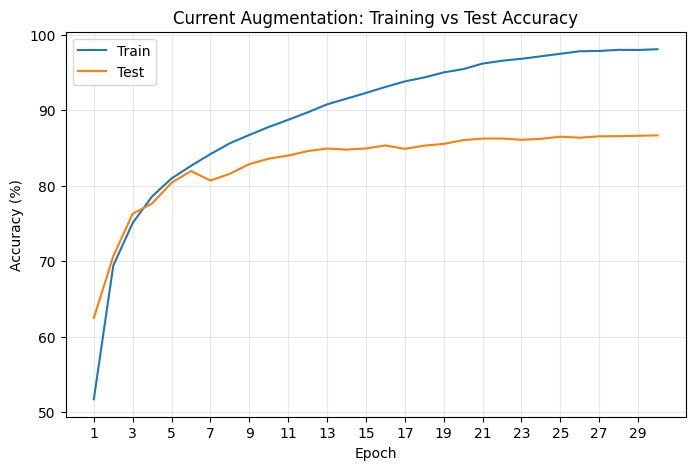

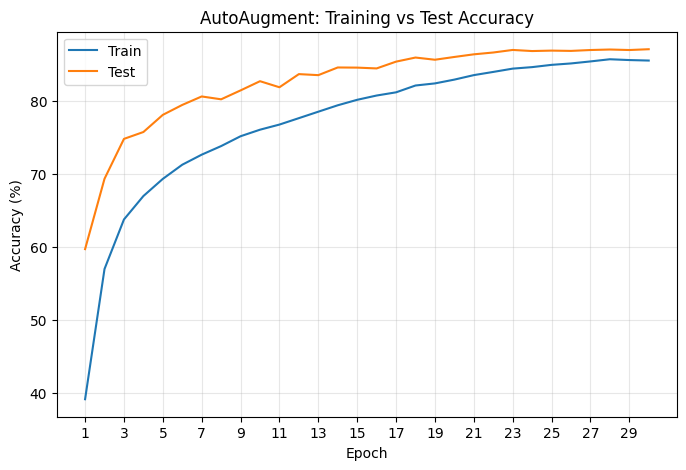

In [23]:
epochs = range(1, LONG_AUG_EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    long_aug_results["Current"]["train"],
    label="Train"
)
plt.plot(
    epochs,
    long_aug_results["Current"]["test"],
    label="Test"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Current Augmentation: Training vs Test Accuracy")
plt.xticks(range(1, LONG_AUG_EPOCHS + 1, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    long_aug_results["AutoAugment"]["train"],
    label="Train"
)
plt.plot(
    epochs,
    long_aug_results["AutoAugment"]["test"],
    label="Test"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("AutoAugment: Training vs Test Accuracy")
plt.xticks(range(1, LONG_AUG_EPOCHS + 1, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##Extended Data Augmentation Comparison

The existing augmentation achieved a best test accuracy of 86.66% at epoch 30. However, training accuracy increased to 98.07%, producing a much larger gap between training and test performance as training progressed.

AutoAugment achieved the strongest result, reaching 87.07% test accuracy at epoch 30. Its training accuracy remained considerably lower at 85.52%, reflecting the increased difficulty of the augmented training images. Despite this, test accuracy continued to improve throughout the run.

This behaviour is much more stable and suggests that AutoAugment provided substantially stronger regularisation and improved generalisation compared with the standard crop-and-flip preprocessing. The longer experiment also confirms that the weaker result observed during the initial 15-epoch screening was likely due to slower convergence rather than poorer final performance.

AutoAugment was therefore selected as the final training augmentation.



## Final Training

The final selected model is trained one more time using the winning architecture, optimisation settings and data augmentation. A longer training run is used because the earlier experiments are intended mainly for model selection rather than final convergence.

Below is another diagram I made using powerpoint showing the final chosen architechture.

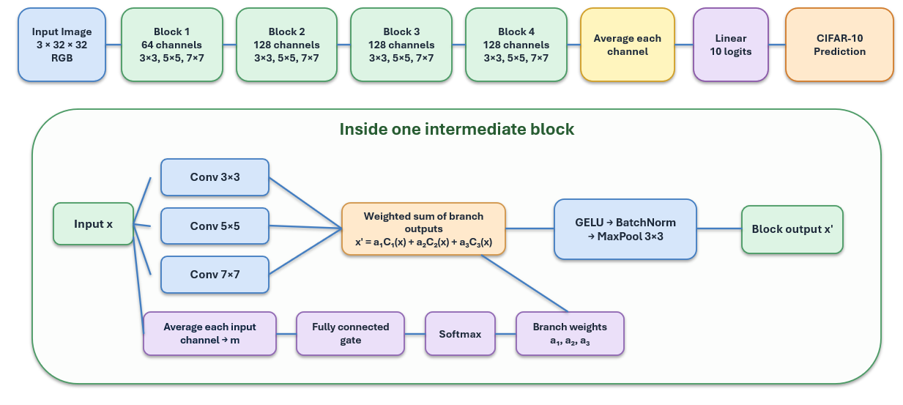


As seen in the diagram, the final architecture consists of 4 intermediate blocks. The first block outputs 64 channels and the remaining three blocks output 128 channels. Each intermediate block contains 3 parallel convolution branches with kernel sizes 3×3, 5×5 and 7×7.

Within each intermediate block, all convolution branches receive the same input x. The average value of each channel in x is used to form the vector m. The vector m is passed through a fully connected gate followed by Softmax to produce the branch weights a1, a2 and a3. These weights are then used to combine the three convolutional branch outputs.

After each block, GELU activation, Batch Normalisation and MaxPool 3×3 are applied before passing the output to the next block. After the final intermediate block, each channel is averaged to form the vector m, which is passed through a linear layer to produce the 10 CIFAR-10 logits.

The final training configuration used the Adam optimiser with an initial learning rate of 0.001,  cosine learning-rate scheduler, AutoAugment and 60 training epochs.


Final augmentation: AutoAugment
Epoch 1/60 | LR: 0.001000 | Train: 39.13% | Test: 59.69%
Epoch 2/60 | LR: 0.000999 | Train: 56.88% | Test: 67.40%
Epoch 3/60 | LR: 0.000997 | Train: 63.41% | Test: 74.36%
Epoch 4/60 | LR: 0.000994 | Train: 66.73% | Test: 74.97%
Epoch 5/60 | LR: 0.000989 | Train: 69.16% | Test: 78.02%
Epoch 6/60 | LR: 0.000983 | Train: 70.98% | Test: 79.60%
Epoch 7/60 | LR: 0.000976 | Train: 72.41% | Test: 79.99%
Epoch 8/60 | LR: 0.000967 | Train: 73.33% | Test: 80.82%
Epoch 9/60 | LR: 0.000957 | Train: 74.59% | Test: 81.16%
Epoch 10/60 | LR: 0.000946 | Train: 75.35% | Test: 82.03%
Epoch 11/60 | LR: 0.000934 | Train: 76.28% | Test: 82.67%
Epoch 12/60 | LR: 0.000920 | Train: 76.96% | Test: 83.11%
Epoch 13/60 | LR: 0.000905 | Train: 77.55% | Test: 82.02%
Epoch 14/60 | LR: 0.000890 | Train: 78.20% | Test: 83.76%
Epoch 15/60 | LR: 0.000873 | Train: 79.15% | Test: 84.04%
Epoch 16/60 | LR: 0.000855 | Train: 79.63% | Test: 84.18%
Epoch 17/60 | LR: 0.000836 | Train: 79.98% | Test

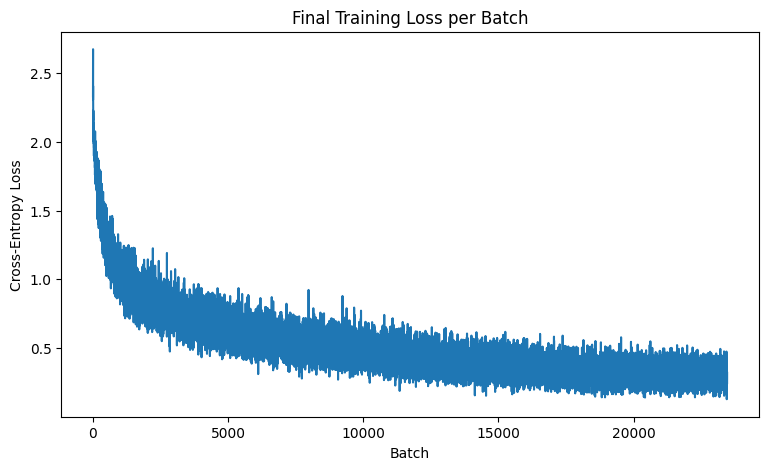

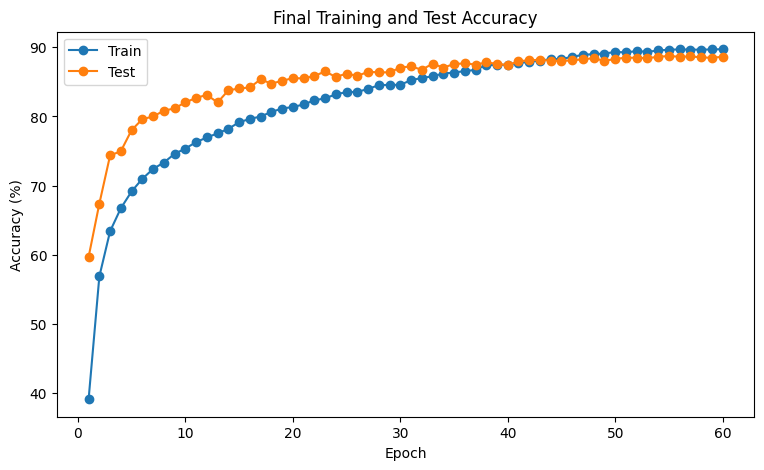

In [25]:
FINAL_EPOCHS = 60

best_augmentation_name = best_long_aug
best_augmentation_transform = long_aug_options[
    best_augmentation_name
]

print("Final augmentation:", best_augmentation_name)


final_train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=False,
    transform=best_augmentation_transform
)


final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


torch.manual_seed(SEED)

final_model = OptimalBlockModel()


final_train_acc, final_test_acc, final_batch_losses = run_model(
    final_model,
    final_train_loader,
    test_loader,
    num_epochs=FINAL_EPOCHS,
    learning_rate=best_learning_rate,
    use_cosine=best_use_cosine
)


final_best_epoch = (
    final_test_acc.index(max(final_test_acc)) + 1
)


print("\nFINAL MODEL RESULT")
print(
    f"Best Test = {max(final_test_acc):.2f}% | "
    f"Epoch = {final_best_epoch}"
)


torch.save(
    final_model.state_dict(),
    "final_cifar10_model.pth"
)


plt.figure(figsize=(9, 5))
plt.plot(final_batch_losses)
plt.xlabel("Batch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Final Training Loss per Batch")
plt.show()


plt.figure(figsize=(9, 5))
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    final_train_acc,
    marker="o",
    label="Train"
)
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    final_test_acc,
    marker="o",
    label="Test"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Final Training and Test Accuracy")
plt.legend()
plt.show()

### Final Model Result and Discussion

Test accuracy continued to improve throughout the longer training run and reached a best value of 88.72% at epoch 55. The final epoch achieved 88.63% and the final 10 epochs remained close to 88% test accuracy showing that performance had largely stabilised by the end of training.

This represents a substantial improvement over the original basic architecture, which achieved a best test accuracy of 26.72%. The final model therefore improved test accuracy by approximately 62% while still preserving the required sequence of intermediate blocks.

Training accuracy reached 89.71% at epoch 60 and remained close to test accuracy, which contrasts with the much larger train-test gap observed when using the standard augmentation. This indicates that AutoAugment provided effective regularisation while allowing the model to continue learning over a longer training period.

Overall, the final result was produced through steady improvements in architecture, activation, gating, pooling, normalisation, optimisation and data augmentation rather than through a single large architectural change.


## Final Model Error Analysis

The best observed test accuracy occurred at epoch 55, reaching 88.72%. During training, the model weights corresponding to the highest test accuracy were retained and restored at the end of the training run. The following error analysis therefore examines this best-performing model.


In [27]:
class_names = test_loader.dataset.classes

final_model.eval()

confusion = torch.zeros(10, 10, dtype=torch.int64)

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        for true, pred in zip(
            labels.cpu(),
            predictions.cpu()
        ):
            confusion[true, pred] += 1

In [28]:
class_accuracy = (
    confusion.diag().float()
    / confusion.sum(dim=1)
    * 100
)

print("PER-CLASS ACCURACY")

for name, acc in zip(
    class_names,
    class_accuracy
):
    print(
        f"{name:10s}: {acc:.2f}%"
    )

PER-CLASS ACCURACY
airplane  : 90.30%
automobile: 95.70%
bird      : 83.10%
cat       : 75.60%
deer      : 88.70%
dog       : 79.80%
frog      : 92.20%
horse     : 94.20%
ship      : 94.60%
truck     : 93.00%


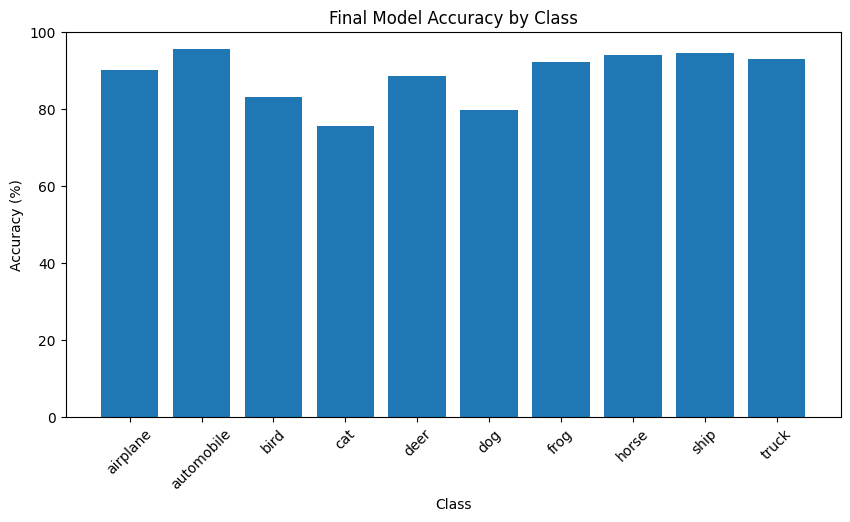

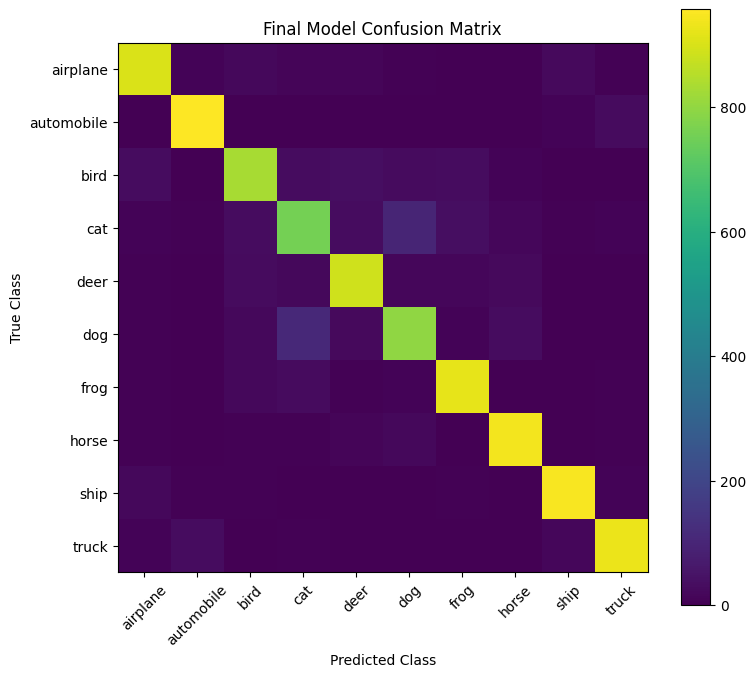

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_names,
    class_accuracy.numpy()
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Class")
plt.title("Final Model Accuracy by Class")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.show()

plt.figure(figsize=(8, 7))

plt.imshow(confusion.numpy())
plt.colorbar()

plt.xticks(
    range(10),
    class_names,
    rotation=45
)

plt.yticks(
    range(10),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Final Model Confusion Matrix")

plt.tight_layout()
plt.show()

In [30]:
errors = confusion.clone()

for i in range(10):
    errors[i, i] = 0

print("MOST COMMON CONFUSIONS")

for _ in range(5):

    index = errors.argmax()

    true_class = (
        index // 10
    ).item()

    predicted_class = (
        index % 10
    ).item()

    count = errors[
        true_class,
        predicted_class
    ].item()

    print(
        f"{class_names[true_class]} -> "
        f"{class_names[predicted_class]}: "
        f"{count}"
    )

    errors[
        true_class,
        predicted_class
    ] = 0

MOST COMMON CONFUSIONS
dog -> cat: 109
cat -> dog: 99
cat -> frog: 36
bird -> deer: 34
cat -> deer: 33


### Error Analysis

The final model performed strongly across most CIFAR-10 classes, but performance was not uniform. Automobile, ship, horse and truck, all achieved accuracies above 93%, while cat and dog were the most difficult classes at 75.60% and 79.80% respectively.

The confusion matrix shows that the largest source of error was between cats and dogs. The model predicted dogs as cats 109 times and cats as dogs 99 times. This makes sense as cats and dogs share a lot of physical similarities making it harder for CNN models to differentiate them.




### Limitations and Future Work

Although the final model achieved a best test accuracy of 88.72%, there are several limitations that could be addressed in future work.

The main practical limitation was computational cost. The project was carried out using the free-tier GPU available through Google Colab and involved a large number of screening experiments followed by longer full-dataset training runs. Consequently, only a relatively small number of carefully selected configurations could be evaluated.

This is particularly relevant when comparing the experimental setup with published CIFAR-10 studies, which commonly use substantially longer training schedules than the 60-epoch final run used here
With greater computational resources, longer screening and training runs could therefore be explored alongside wider and deeper model configurations.

The width and depth experiments both showed that increasing model capacity was beneficial, which is also consistent with the motivation behind Wide Residual Networks [2], where increased width is used as an alternative to simply increasing depth.

Residual connections would also be a useful extension. Existing architectures such as ResNet show that skip connections can improve optimisation in deeper CNNs. A future version could therefore investigate adding residual connections around the intermediate blocks while preserving the required parallel convolution and learned branch weighting mechanism.

The final model showed little evidence of substantial overfitting, with training and test accuracy remaining close during the later stages of training. For this reason, additional regularisation methods were not explored further. If a larger train-test gap had remained, further experiments could have investigated standard NN regularisation techniques such as dropout, L2 weight decay and early stopping. These were avoided in the final experimental pipeline because the selected AutoAugment configuration was already providing effective regularisation, and additional screening would have increased computational cost.

Finally, the remaining errors suggest that additional work could focus specifically on difficult animal classes such as cats and dogs. More targeted augmentation, additional model capacity or further analysis of the learned branch weights may help determine whether different convolutional scales are more useful for these visually similar classes.

Overall, the project shows that substantial performance gains can be achieved while keeping the required architecture recognisable, but further improvements would likely require increased computational resources and more extensive architectural experimentation.


### References

[1] K. He, X. Zhang, S. Ren and J. Sun, “Deep Residual Learning for Image Recognition,” in *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2016.

[2] S. Zagoruyko and N. Komodakis, “Wide Residual Networks,” in *Proceedings of the British Machine Vision Conference (BMVC)*, 2016.

[3] G. Huang, Z. Liu, L. van der Maaten and K. Q. Weinberger, “Densely Connected Convolutional Networks,” in *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2017.

[4] T. DeVries and G. W. Taylor, “Improved Regularization of Convolutional Neural Networks with Cutout,” arXiv:1708.04552, 2017.

[5] E. D. Cubuk, B. Zoph, D. Mane, V. Vasudevan and Q. V. Le, “AutoAugment: Learning Augmentation Policies from Data,” in *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, 2019.


[1]: https://openaccess.thecvf.com/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html "CVPR 2016 Open Access Repository"

[2]: https://bmva-archive.org.uk/bmvc/2016/papers/paper087/index.html "BMVC 2016"

[3]: https://openaccess.thecvf.com/content_cvpr_2017/html/Huang_Densely_Connected_Convolutional_CVPR_2017_paper.html "CVPR 2017 Open Access Repository"

[4]: https://arxiv.org/abs/1708.04552 "Improved Regularization of Convolutional Neural Networks with Cutout"

[5]: https://openaccess.thecvf.com/content_CVPR_2019/html/Cubuk_AutoAugment_Learning_Augmentation_Strategies_From_Data_CVPR_2019_paper.html "CVPR 2019 Open Access Repository"

